# How reproducible is ascidian embryogenesis?

*Nine embryos of* Phallusia mammillata *compared cell by cell with `lineagetree`*

Ascidian embryos develop with an invariant pattern of cleavages: every cell
has a name, after Conklin (1905), and the same cell can be found again in
every embryo. Guignard et al. ([Science 369, eaar5663, 2020](https://doi.org/10.1126/science.aar5663))
imaged *Phallusia mammillata* embryos by light-sheet microscopy every two
minutes, from the 64-cell stage to the initial tailbud, and segmented and
tracked all their cells with ASTEC. They found that embryos are reproducible
down to single cells: matching cells differ by less than 10% in lifespan and
volume, they share most of their neighbours, and the areas of most of their
contacts vary by less than 20%. They also showed that inductions in this embryo depend
on the area of contact between the signalling and the responding cells, which
gives this geometric precision a developmental meaning, and that the
divisions whose daughters make different lineages are those where fates are
restricted.

This notebook measures how variable these embryos are, with all the
quantities that the ASTEC files provide: the timing of the divisions, the
volumes and shapes of the cells, the orientation of their divisions, their
positions, their contacts, and the lineage trees themselves, compared with the
unordered tree edit distance (UTED) of `lineagetree`. The question it keeps
asking is the one of Guignard et al.: is a cell more different from the same
cell in another embryo than from its mirror image in the same embryo?

The data are the ASTEC property files of the
[figshare project](https://figshare.com/projects/Phallusia_mammillata_embryonic_development/64301)
of the Lemaire lab, in `data/Pmmamm/`. Seven of them are the 2023 releases
(`-v2`) of the embryos of Guignard et al., named with the reference atlas of
Biasuz et al. ([bioRxiv, 2025](https://doi.org/10.1101/2025.10.13.681089));
the other two, Astec-Pm6 and Astec-Pm10, are 2020 releases that the atlas did
not use. The helpers of the notebook are in `ascidian_tools.py`.

### In short

- **One clock per embryo.** The embryos develop at different paces: the
  slowest one takes 1.34 times as long as the fastest. A single linear
  transformation of time per embryo aligns the birth of each cell to within
  a median of 2 to 3 minutes, and it fits all the founder lines and
  generations alike: the cell cycles of an embryo are all stretched by the
  same factor.
- **Cycle lengths** of matched cells differ by a median of 4% between
  embryos, as between the two sides of one embryo. **Divisions** happen
  within a standard deviation of 3.6 minutes. The 76- and 112-cell stages
  are made of exactly the same cells in all the embryos; the order of the
  divisions between them varies.
- **Sister cells** divide together to within 1.5 minutes, except in seven
  pairs where one sister reproducibly divides 9 to 57 minutes after the
  other. Most of these pairs are also unequal in volume and make different
  tissues.
- **Volumes** of matched cells differ by a median of 10% between embryos and
  8% between the two sides. 26 divisions are reproducibly unequal, and the
  smaller daughter divides later in 83% of them.
- **Divisions follow Hertwig's rule** (median |cos| of 0.90 with the long axis
  of the mother), and their orientation is reproduced to a median of 12
  degrees across embryos, more precisely for unequal divisions.
- **Positions and contacts** are reproducible but drift with time: matched
  cells sit 0.3 to 0.9 cell radius apart after registration, and share 87%
  of their contact surface at the 64-cell stage, 71% at the start of
  neurulation. Large contacts are always there and vary by 10 to 20%;
  contacts under 2% of the surface of a cell come and go.
- **Gastrulation is as precise as the divisions:** once the clocks are
  aligned, each tissue leaves the surface of the embryo at the same time in
  all the embryos, to within 1 to 4.5 minutes (standard deviations), the
  germ line excepted.
- **The lineage trees** of matched cells differ by a median UTED of 9%
  between embryos and 7% between the two sides, once time is aligned (17%
  without). Sister lineages diverge more when the daughters make different
  tissues, and adding the volumes of the cells to the tree distance brings
  out the unequal divisions.
- **Timing and geometry vary independently:** cells with variable timing do
  not have variable positions or contacts.
- **The B7.7 division** stands out: on most sides it gives a tiny cell an
  hour before a second division, on the others a single equal division. And
  the two 2020 reconstructions disagree with the seven others on the vegetal
  lineages, more than the seven disagree with each other.

In [18]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, spearmanr

import lineagetree
import ascidian_tools as at

warnings.filterwarnings("ignore", message="More than 100 comparisons")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
print("lineagetree", lineagetree.__version__)

lineagetree 3.3.1


## 1. Nine embryos

`read_from_ASTEC` reads each file into a `LineageTree`: one node per cell and
time point, with the properties of the file (volume, contacts, cell names,
tissues...). The names are stored in the `label` property;
`change_labels("label")` makes them the labels of the tree. The nine trees go
into a `LineageTreeManager`, which compares lineages across embryos.

The table checks the names. The seven v2 embryos are named without a single
inconsistency: no cell changes name during its life, no name is used twice,
and the name of every daughter follows from that of its mother. The two 2020
reconstructions are named less completely (Astec-Pm10 only until its 24th time
point) and with a few errors. The analyses that match cells by name therefore
use the seven v2 embryos; the two others come back at the end.

In [19]:
embryos = at.load_embryos()
V2 = [name for name, lT in embryos if lT.version == "v2"]
V1 = [name for name, lT in embryos if lT.version == "v1"]
tables = {name: at.cell_table(lT) for name, lT in embryos}

overview = {}
for name, lT in embryos:
    counts = at.cell_counts(lT)
    overview[name] = {
        "release": lT.version,
        "time points": len(counts),
        "cells at start": counts.iloc[0],
        "cells at end": counts.iloc[-1],
        "divisions": sum(len(s) == 2 for s in lT.successor.values()),
        **at.naming_report(lT),
    }
overview = pd.DataFrame(overview).T
overview["named"] = overview["named"].astype(float).map("{:.0%}".format)
overview

,release,time points,cells at start,cells at end,divisions,named,fully named until,several names,duplicates,bad daughters
Phmamm-1-v2,v2,180,64,702,639,65%,123,0,0,0
Phmamm-3-v2,v2,90,46,325,280,100%,89,0,0,0
Phmamm-4-v2,v2,90,35,272,237,100%,89,0,0,0
Phmamm-5-v2,v2,90,56,331,276,100%,88,0,0,0
Phmamm-7-v2,v2,79,43,218,175,100%,82,0,0,0
Phmamm-8-v2,v2,88,64,397,333,100%,88,0,0,0
Phmamm-9-v2,v2,63,72,298,227,100%,58,2,0,0
Astec-Pm6,v1,89,42,311,269,98%,5,0,7,3
Astec-Pm10,v1,163,47,771,736,48%,24,51,59,3


### What a file holds

Each cell at each time point has a volume, a barycentre, a surface, the areas
of its contacts with each neighbour (the outside of the embryo counts as a
neighbour), the principal axes of its shape, and the tissues that its
descendants will make. Volumes are in voxels and areas in voxel faces, so
they are compared as fractions: of the volume of the embryo, or of the surface
of the cell. Here is A7.1, an endoderm precursor of the 64-cell stage, in the
middle of its life.

In [20]:
reference = embryos[at.REFERENCE]
row = tables[at.REFERENCE].loc["a7.0001_"]
node = at.node_before(reference, row["last"], row["frames"] // 2)  # the middle of its life
contacts = at.neighbourhood(reference, node)
print(f"{at.conklin('a7.0001_')} in {at.REFERENCE}: time points {row['start']} to {row['end']}, "
      f"then it divides into {[at.conklin(d) for d in at.daughters('a7.0001_')]}")
print(f"  volume {reference.volume[node]:,} voxels ({row['volume']:.1%} of the embryo), surface {reference.cell_surface[node]:,.0f}")
print(f"  sum of its contact areas: {sum(reference.contact[node].values()):,.0f}")
print("  contacts, as fractions of its surface:",
      {(at.conklin(k) if at.parse_name(k) else k): round(v, 2) for k, v in sorted(contacts.items(), key=lambda kv: -kv[1])})
print("  tissues of its descendants:", reference.cell_tissue_fate[node])

A7.1 in Phmamm-8-v2: time points 1 to 35, then it divides into ['A8.1', 'A8.2']
  volume 1,139,005 voxels (2.0% of the embryo), surface 80,645
  sum of its contact areas: 80,645
  contacts, as fractions of its surface: {'A7.1*': 0.17, 'B7.1': 0.16, 'A7.2': 0.14, 'A7.5': 0.11, 'B7.1*': 0.07, 'a8.32': 0.06, 'a8.31': 0.05, 'outside': 0.04, 'a8.32*': 0.04, 'a8.31*': 0.03, 'A7.2*': 0.03, 'a8.24': 0.03, 'a8.23': 0.02, 'b7.16': 0.01, 'B7.2': 0.01, 'b7.16*': 0.01, 'a8.24*': 0.01, 'a8.30': 0.0}
  tissues of its descendants: ['Anterior Head Endoderm']


### Names and tissues

A name such as `a7.0009_` reads: anterior half (`a`), 7th generation (the
64-cell stage), index 9, side `_`. ASTEC writes the letter in lowercase for
all cells; the four founder lines of the 8-cell stage, A4.1 (anterior
vegetal), B4.1 (posterior vegetal), a4.2 (anterior animal) and b4.2 (posterior
animal), are told apart by the index: at generation *g*, the vegetal cells
have the indices 1 to 2<sup>*g*-4</sup>. `at.conklin` writes the usual form,
`a7.9`. The two sides are written `_` and `*` (the `*` side is the right one
in the convention of Biasuz et al.); a cell and its bilateral homologue have
the same name with the other side.

The tissues come from the `cell_tissue_fate` property of the files: for each
cell, the tissues that its descendants contribute to. They are grouped into
ten tissues (epidermis, neural plate, notochord, muscle, mesenchyme, trunk
mesoderm, endoderm, germ line, tail tip, and "mixed" for cells whose
descendants make several of them).

In [21]:
tissues = at.tissue_of({e: tables[e] for e in V2})
fates = at.fates_of(embryos, {e: tables[e] for e in V2})
for e in tables:
    tables[e]["tissue"] = tissues.reindex(tables[e].index).fillna("unknown")
sixty_four = [n for n in tissues.index if at.parse_name(n)[1] == 7]
print("tissue of the 64 cells of the 64-cell stage:", tissues[sixty_four].value_counts().to_dict())

tissue of the 64 cells of the 64-cell stage: {'epidermis': 22, 'endoderm': 10, 'mixed': 10, 'neural': 8, 'notochord': 4, 'muscle': 4, 'trunk mesoderm': 2, 'germ line': 2, 'mesenchyme': 2}


The longest movie, Phmamm-1-v2, goes from the 64-cell stage to the initial
tailbud (rotate the views with the mouse). After its 123rd time point, not all
cells are named; they take here the tissue of their closest named ancestor.

In [22]:
P1 = embryos["Phmamm-1-v2"]
counts_P1 = at.cell_counts(P1)
snapshot_times = [int((counts_P1 - n).abs().idxmin()) for n in (64, 112, 250, 700)]
at.embryo_snapshots(P1, snapshot_times, tissues, title="Phmamm-1-v2, from the 64-cell stage to the initial tailbud").show()

## 2. One clock for all the embryos

The movies start at different stages (35 to 72 cells) and the embryos do not
develop at the same pace: plotted against the time points of the movies,
their numbers of cells drift apart. Comparing two embryos cell by cell first
requires a common time axis.

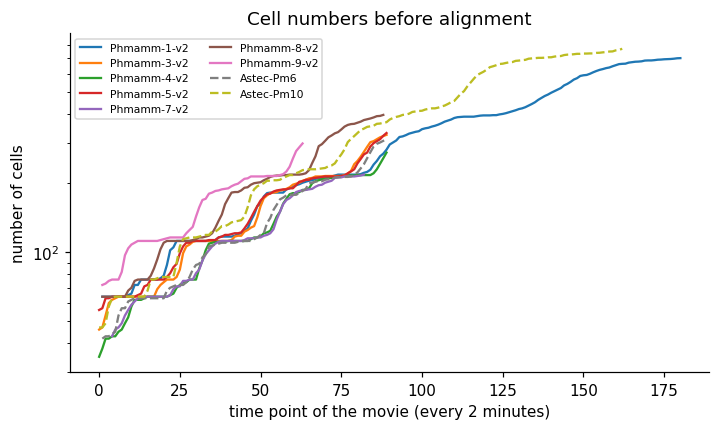

In [23]:
counts = {name: at.cell_counts(lT) for name, lT in embryos}
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, c in counts.items():
    ax.plot(c.index, c.values, lw=1.5, ls="-" if name in V2 else "--", label=name)
ax.set(xlabel="time point of the movie (every 2 minutes)", ylabel="number of cells", yscale="log",
       title="Cell numbers before alignment")
ax.legend(fontsize=7, ncol=2)
plt.show()

### A linear alignment on the births of the cells

Each embryo `e` gets a slope `a` and an offset `b`: its time point `t`
corresponds to time point `a t + b` of the reference embryo, Phmamm-8-v2.
`at.TimeAlignment` fits them on the birth times of all the named cells: each
embryo is aligned on the median birth time of each cell in the other
embryos, the medians are updated, and the fits are repeated until they stop
changing. A median only uses the embryos whose movie covers the birth with 20
minutes to spare: near the end of a movie, only the cells born early in that
embryo are seen, which would bias the alignment.

The reference time is converted to minutes post fertilization with the
`embryo_time_post_fertilization` and `embryo_time_interval` properties of the
files (time point *t* of Phmamm-8-v2 is at 240 + 2*t* minutes).

The table compares the slopes with two other estimates: the alignment of the
curves of cell numbers, which is how Guignard et al. aligned their embryos,
and the alignment stored in the files by the naming pipeline. The first one
agrees within 2%; the stored one is 2 to 5% lower for every embryo, a
difference of method that does not change the conclusions below. The two 2020
reconstructions, whose names are not reliable enough, are aligned on their
cell numbers.

The slopes range from 0.75 to 1: in two minutes, Phmamm-1-v2 develops as much
as the reference in 1.5 minutes. The medians of the absolute deviations of
the births from the other embryos are 2 to 3 minutes, about one time point.

In [24]:
alignment = at.TimeAlignment({e: tables[e] for e in V2}, references=dict(embryos))

# the same alignment, fitted on the curves of cell numbers instead of the names
curve = at.count_curve(counts, alignment, V2)
by_counts = {}
for e in counts:
    start = (alignment.slope[e], alignment.offset[e]) if e in V2 else (0.9, 0.0)
    by_counts[e] = at.fit_to_count_curve(counts[e], curve, start)
for e in V1:  # their names are not reliable enough: they are aligned on their cell numbers
    alignment.add_embryo(e, *by_counts[e], (counts[e].index.min(), counts[e].index.max()))

summary = alignment.summary()
summary["slope from cell numbers"] = [by_counts[e][0] for e in summary.index]
summary["slope in the ASTEC file"] = [
    next(iter(embryos[e].embryo_time_interval.values())) / alignment.interval if hasattr(embryos[e], "embryo_time_interval") else np.nan
    for e in summary.index
]
summary.round(3)

,slope,offset,minutes per time point,start (min),end (min),births,median |deviation| (min),slope from cell numbers,slope in the ASTEC file
Phmamm-1-v2,0.749,1.932,1.497,245.361,513.395,544,2.637,0.757,0.728
Phmamm-3-v2,0.909,-6.246,1.818,227.509,389.309,310,1.936,0.901,0.884
Phmamm-4-v2,0.898,-11.615,1.795,216.769,376.526,306,2.543,0.897,0.881
Phmamm-5-v2,0.858,-2.868,1.717,234.264,387.040,308,3.189,0.861,0.823
Phmamm-7-v2,0.875,-11.051,1.750,224.900,361.423,278,2.555,0.877,0.831
Phmamm-8-v2,1.000,0.000,2.000,242.000,416.000,566,3.121,1.017,1.000
Phmamm-9-v2,0.961,9.227,1.922,260.376,379.568,208,2.118,0.948,0.917


After alignment, the curves of cell numbers of the nine embryos superimpose,
with the plateaus of the synchronous division waves at 64, 76, 112 and
around 200 cells (left). On the right, each point is the birth of a cell: one
straight line per embryo, with its own slope.

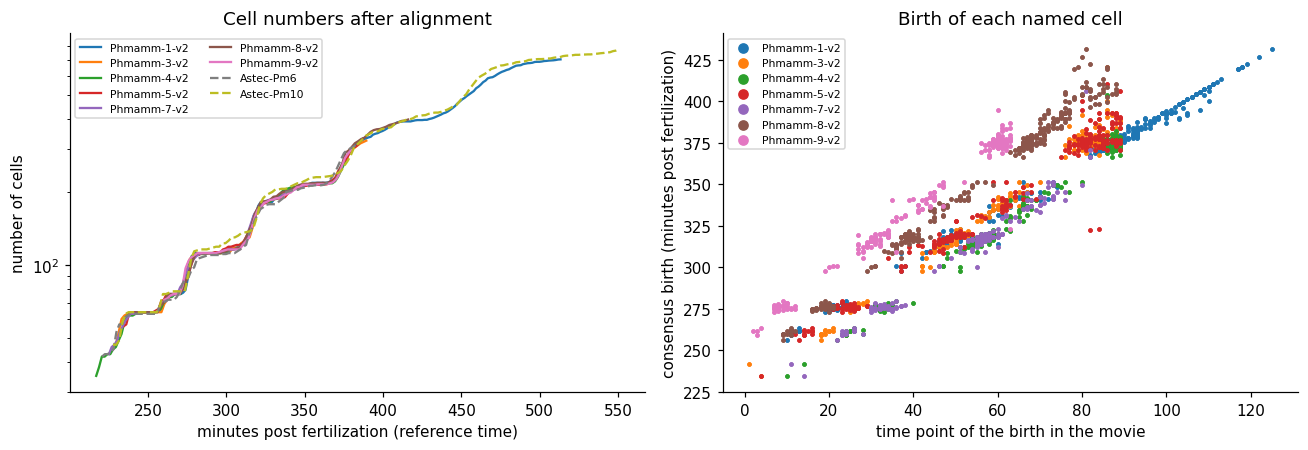

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for name in V2 + V1:
    c = counts[name]
    ax.plot(alignment.minutes(name, c.index.values), c.values, lw=1.5, ls="-" if name in V2 else "--", label=name)
ax.set(xlabel="minutes post fertilization (reference time)", ylabel="number of cells", yscale="log",
       title="Cell numbers after alignment")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
consensus_birth = alignment.consensus("birth")
for name in V2:
    b = tables[name].birth.dropna()
    ok = consensus_birth.reindex(b.index).notna()
    ax.scatter(b[ok], alignment.start_minutes + alignment.interval * consensus_birth[b.index[ok]], s=4, label=name)
ax.set(xlabel="time point of the birth in the movie", ylabel="consensus birth (minutes post fertilization)",
       title="Birth of each named cell")
ax.legend(fontsize=7, markerscale=3)
plt.tight_layout()
plt.show()

### Is one linear transformation enough?

If the pace of an embryo changed during its development, the deviations of
its births would drift with time. They do not: their medians stay within 5
minutes of zero over the whole movies. What remains is a small structure
around 290 minutes, where some embryos are a few minutes early and others a
few minutes late on the same division wave.

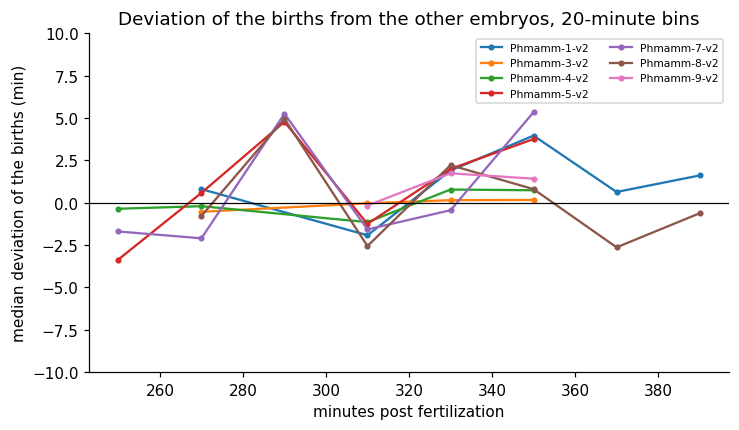

,births,median deviation (min),robust SD of the deviations (min),births more than 20 min off
Phmamm-1-v2,544.0,0.64,3.76,0.0
Phmamm-3-v2,310.0,-0.13,2.82,0.0
Phmamm-4-v2,306.0,0.06,3.79,0.0
Phmamm-5-v2,308.0,0.16,4.67,4.0
Phmamm-7-v2,278.0,-1.40,4.04,0.0
Phmamm-8-v2,566.0,-0.81,4.19,2.0
Phmamm-9-v2,208.0,0.26,3.16,2.0


In [26]:
birth_deviation = alignment.deviations("birth")
birth_minutes = pd.DataFrame({e: alignment.minutes(e, tables[e].birth) for e in V2})
fig, ax = plt.subplots(figsize=(7.5, 4))
spread_by_embryo = {}
for e in V2:
    d = pd.concat([birth_minutes[e], birth_deviation[e]], axis=1, keys=["m", "d"]).dropna()
    bins = (d.m // 20) * 20 + 10
    profile = d.groupby(bins).d.agg(["median", "size"])
    profile = profile[profile["size"] >= 10]
    ax.plot(profile.index, profile["median"], marker="o", ms=3, label=e)
    spread_by_embryo[e] = {"births": len(d), "median deviation (min)": d.d.median(),
                           "robust SD of the deviations (min)": 1.4826 * (d.d - d.d.median()).abs().median(),
                           "births more than 20 min off": int((d.d.abs() > 20).sum())}
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="minutes post fertilization", ylabel="median deviation of the births (min)", ylim=(-10, 10),
       title="Deviation of the births from the other embryos, 20-minute bins")
ax.legend(fontsize=7, ncol=2)
plt.show()
pd.DataFrame(spread_by_embryo).T.round(2)

A stronger test: if a single factor stretches the whole development of an
embryo, the cycle of every cell must be stretched by it, whatever its
generation and its founder line. The table divides the cycle length of each
cell by its median over the embryos (all in reference minutes): the medians
are 0.98 to 1.04 in every generation and every founder line. The embryos
differ by a global pace, most likely set by small differences of temperature
between the experiments, and all the lineages follow it together.

In [27]:
cycles = at.cycle_lengths(alignment)
ratio = cycles.div(cycles.median(axis=1), axis=0)
cells_info = pd.DataFrame({"gen": [at.parse_name(n)[1] for n in ratio.index],
                           "line": [at.founder(n) for n in ratio.index]}, index=ratio.index)
by_group = {}
for e in V2:
    r = ratio[e].dropna()
    by_group[e] = {**{f"generation {g}": v for g, v in r.groupby(cells_info.gen.reindex(r.index)).median().items()},
                   **{f"{line}-line": v for line, v in r.groupby(cells_info.line.reindex(r.index)).median().items()}}
print("cycle length of each cell divided by its median over the embryos, median by group:")
pd.DataFrame(by_group).T.round(3)

cycle length of each cell divided by its median over the embryos, median by group:


,generation 8,generation 9,generation 10,A-line,B-line,a-line,b-line,generation 7
Phmamm-1-v2,0.995,1.000,1.0,1.000,1.000,1.000,1.000,NaN
Phmamm-3-v2,1.025,0.984,NaN,1.000,1.042,1.026,1.027,NaN
Phmamm-4-v2,1.013,NaN,NaN,0.984,1.000,1.015,1.016,1.0
Phmamm-5-v2,0.992,1.008,NaN,1.000,0.990,1.007,0.981,NaN
Phmamm-7-v2,1.000,NaN,NaN,1.011,0.982,0.995,0.997,NaN
Phmamm-8-v2,0.994,0.992,NaN,0.992,0.982,0.989,1.000,NaN
Phmamm-9-v2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Timing of the divisions

### Cell cycles

With the time aligned, the cycle of each cell is measured in reference
minutes in each embryo. Cells whose birth and division are not both covered
by a movie, with margin, are left out in that embryo, so that the end of a
movie does not select the short cycles.

95 cells with a complete cycle in at least 4 embryos; cycle lengths from 40 to 82 minutes
coefficient of variation across embryos: median 3.9%
relative difference, between embryos: median 4.0%, mean 5.0%, under 10% for 89% (1296 pairs)
relative difference, left/right: median 3.7%, mean 5.4%, under 10% for 84% (535 pairs)
correlation of the deviations of the left and right homologues in the same embryo: 0.34 (535 pairs)
median coefficient of variation by tissue: {'epidermis': 0.039, 'mesenchyme': 0.033, 'mixed': 0.047, 'muscle': 0.041, 'neural': 0.035, 'notochord': 0.056, 'trunk mesoderm': 0.069}


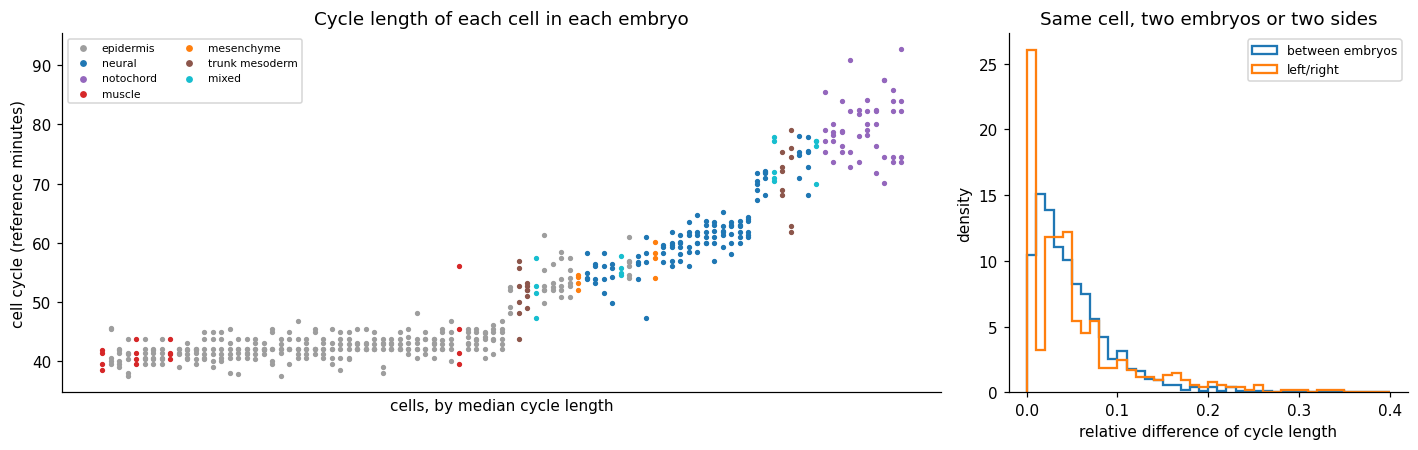

In [28]:
enough = cycles.notna().sum(axis=1) >= 4
cv = cycles[enough].std(axis=1) / cycles[enough].mean(axis=1)
cycle_diffs = at.relative_differences(cycles)
r_sides, n_sides = at.side_correlation(cycles)
print(f"{enough.sum()} cells with a complete cycle in at least 4 embryos; cycle lengths from "
      f"{cycles[enough].median(axis=1).min():.0f} to {cycles[enough].median(axis=1).max():.0f} minutes")
print(f"coefficient of variation across embryos: median {cv.median():.1%}")
for comparison, d in cycle_diffs.groupby("comparison").difference:
    print(f"relative difference, {comparison}: median {d.median():.1%}, mean {d.mean():.1%}, under 10% for {(d < 0.1).mean():.0%} ({len(d)} pairs)")
print(f"correlation of the deviations of the left and right homologues in the same embryo: {r_sides:.2f} ({n_sides} pairs)")
print("median coefficient of variation by tissue:", cv.groupby(tissues.reindex(cv.index)).median().round(3).to_dict())

order = cycles[enough].median(axis=1).sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
for i, name in enumerate(order):
    values = cycles.loc[name].dropna()
    ax.scatter([i] * len(values), values, s=6, color=at.TISSUE_COLORS.get(tissues.get(name), "#999"))
ax.set(xticks=[], xlabel="cells, by median cycle length", ylabel="cell cycle (reference minutes)",
       title="Cycle length of each cell in each embryo")
for tissue, color in at.TISSUE_COLORS.items():
    if tissue in set(tissues.reindex(order)):
        ax.scatter([], [], color=color, label=tissue, s=12)
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
for comparison, d in cycle_diffs.groupby("comparison").difference:
    ax.hist(d, bins=np.linspace(0, 0.4, 41), histtype="step", density=True, lw=1.5, label=comparison)
ax.set(xlabel="relative difference of cycle length", ylabel="density", title="Same cell, two embryos or two sides")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Cycle lengths range from 40 minutes (the epidermis and the first muscle cells,
which divide fastest) to 80 minutes (the notochord), and the same cell has the
same cycle in every embryo, to a median coefficient of variation of 4%. This
is the "less than 10%" of Guignard et al., and the two sides of an embryo
differ by as much as two embryos.

The deviations of the left and right homologues of an embryo are correlated
(0.34): part of the variability is shared by the two sides, so not all of it
is noise of single cells. The alignment removes the pace of the whole embryo,
but each embryo keeps small deviations of its own, shared by both sides.

### Division times

The deviation of each division from its median in the other embryos measures
the precision of the timing, in reference minutes. The standard deviation is
3.6 minutes for a typical division, a little less in the neural plate and the
epidermis, more in the endoderm (6.6 min) and much more in the mesenchyme,
because of one cell, B7.7 (section 10). The table shows that no founder line
is systematically early or late in any embryo (all within 4 minutes).

In [29]:
division_deviation = alignment.deviations("division")
observed = division_deviation.notna().sum(axis=1) >= 4
spread = division_deviation[observed].std(axis=1)
division_info = pd.DataFrame({"tissue": tissues.reindex(spread.index), "gen": [at.parse_name(n)[1] for n in spread.index],
                              "line": [at.founder(n) for n in spread.index], "spread": spread})
print(f"{observed.sum()} divisions seen in at least 4 embryos; standard deviation of their times: median {spread.median():.1f} min")
print("by generation of the mother:", division_info.groupby("gen").spread.median().round(1).to_dict())
print("by tissue:", division_info.groupby("tissue").spread.median().round(1).sort_values().to_dict())
print("most variable:", {at.conklin(n): round(v, 1) for n, v in spread.sort_values().tail(8).items()})
by_line = division_deviation[observed].groupby(division_info.line).median().T
print("median advance (-) or delay (+) of the divisions of each founder line, by embryo (min):")
by_line.round(1)

157 divisions seen in at least 4 embryos; standard deviation of their times: median 3.6 min
by generation of the mother: {7: 3.7, 8: 3.5, 9: 5.0}
by tissue: {'neural': 3.3, 'epidermis': 3.5, 'mixed': 3.8, 'trunk mesoderm': 4.7, 'notochord': 4.9, 'muscle': 5.1, 'endoderm': 6.6, 'mesenchyme': 16.1}
most variable: {'A8.5': 7.8, 'B8.5*': 7.9, 'B8.7*': 8.6, 'B8.5': 8.8, 'A8.12': 10.3, 'A8.14': 11.2, 'B7.7': 23.4, 'B7.7*': 29.5}
median advance (-) or delay (+) of the divisions of each founder line, by embryo (min):


line,A,B,a,b
Phmamm-1-v2,-0.5,0.6,0.2,2.4
Phmamm-3-v2,0.4,2.1,-0.6,-0.8
Phmamm-4-v2,-0.4,1.9,-1.1,0.2
Phmamm-5-v2,-1.6,-3.5,3.9,-0.9
Phmamm-7-v2,1.6,-2.0,2.2,-2.7
Phmamm-8-v2,-1.0,0.6,-3.3,2.9
Phmamm-9-v2,1.7,-0.9,1.3,-0.9


In the heatmap, a column is a division and a row an embryo. Columns of the
same colour are divisions that are early or late in all the embryos; there are
few. Rows of the same colour would be embryos with their own pace, removed by
the alignment.

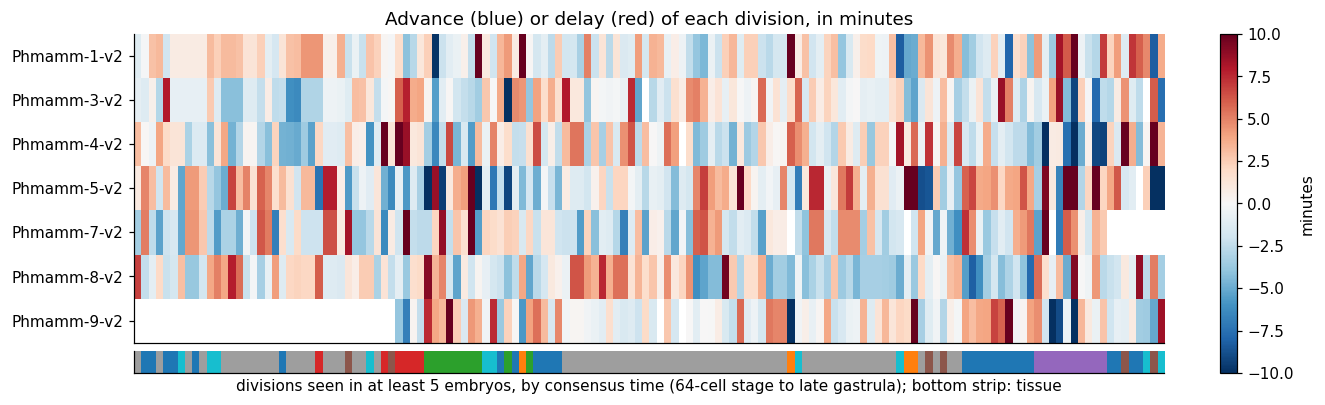

In [30]:
consensus_division = alignment.consensus("division")
shown = division_deviation[division_deviation.notna().sum(axis=1) >= 5]
shown = shown.loc[consensus_division.reindex(shown.index).sort_values().index]
fig, (ax, strip) = plt.subplots(2, 1, figsize=(13, 4), sharex=True, gridspec_kw={"height_ratios": [7, 0.5], "hspace": 0.05})
image = ax.imshow(shown.T.values, aspect="auto", cmap="RdBu_r", vmin=-10, vmax=10, interpolation="nearest")
ax.set(yticks=range(len(V2)), yticklabels=V2, title="Advance (blue) or delay (red) of each division, in minutes")
colors = [at.TISSUE_COLORS.get(tissues.get(n), "#999") for n in shown.index]
strip.imshow([[plt.matplotlib.colors.to_rgb(c) for c in colors]], aspect="auto")
strip.set(yticks=[], xticks=[], xlabel="divisions seen in at least 5 embryos, by consensus time (64-cell stage to late gastrula); bottom strip: tissue")
plt.colorbar(image, ax=[ax, strip], label="minutes", fraction=0.02)
plt.show()

### The order of the divisions

At the 76-cell and 112-cell stages, the seven embryos are made of exactly the
same cells: these are the long plateaus between synchronous division waves.
Between them, during the waves, the cells divide in a different order in each
embryo, and the fraction of cells found in all the embryos falls to 40%. The
waves become less synchronous later, and the stages around 250 cells share
only half of their cells. Biasuz et al. traced such heterochronies to the
divisions of the epidermis.

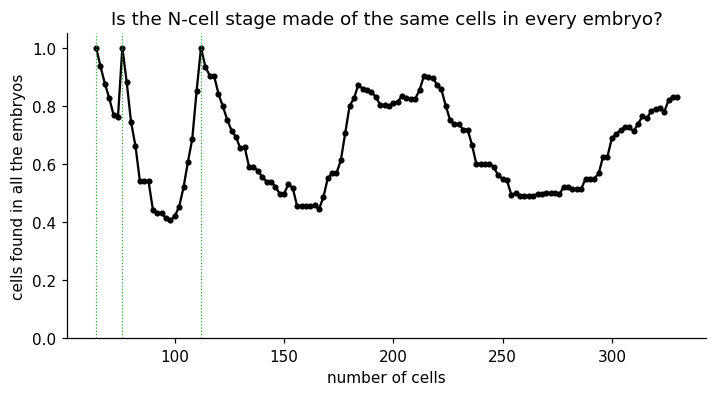

cells    64   76   112  150   184   220   250   300
embryos  6.0  7.0  7.0  7.0  7.00  6.00  6.00  4.00
shared   1.0  1.0  1.0  0.5  0.87  0.87  0.55  0.69


In [31]:
composition = at.stage_composition(embryos, V2, range(64, 331, 2))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(composition.index, composition.shared, marker=".", color="k")
for n in (64, 76, 112):
    ax.axvline(n, color="tab:green", lw=0.8, ls=":")
ax.set(xlabel="number of cells", ylabel="cells found in all the embryos",
       title="Is the N-cell stage made of the same cells in every embryo?", ylim=(0, 1.05))
plt.show()
print(composition.loc[[64, 76, 112, 150, 184, 220, 250, 300]].round(2).T)

### Sister cells

Most sisters divide together: 24 of the 38 pairs observed at least six times
are within 2 minutes on average, with a standard deviation of 1.5 minutes. In
seven pairs, one sister divides 9 to 57 minutes after the other, in every
embryo and on both sides. 84% of the variance of the asynchrony comes from the
identity of the pair: it is programmed, not noise.

In six of the seven pairs, the late sister is the smaller one (1.5 to 3.5
times), and in five the two sisters make different tissues: the notochord
precursor B8.6 divides 21 minutes after its sister B8.5 (mesenchyme), b8.17
(muscle and tail tip) and b8.19 (neural plate) about 20 minutes after their
epidermal sisters, the endoderm precursor A7.5 33 minutes after A7.6 (trunk
mesoderm). The delay of the mesenchyme precursor B7.7 after its sister B7.8
(muscle) is the largest and by far the most variable (27 minutes of SD,
section 10).

38 sister pairs seen at least 6 times (both sides, all embryos); 84% of the variance of their asynchrony comes from the identity of the pair
24 pairs within 2 min on average: SD of their asynchrony 1.5 min
7 pairs where the same sister divides first, by more than 5 min and more than 2 SD:


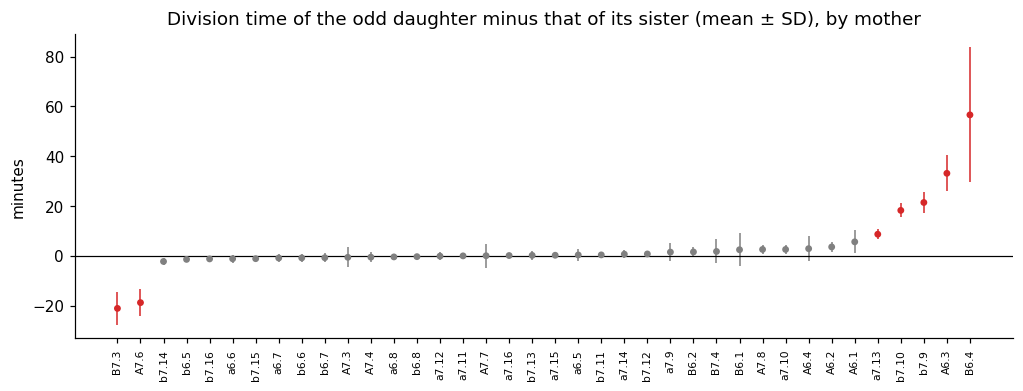

,mother,divides first,then,delay (min),SD (min),volume of the first / the second,tissues of the first,tissues of the second
0,B7.3,B8.5,B8.6,21.11,6.49,3.48,mesenchyme,notochord
1,A7.6,A8.11,A8.12,18.79,5.54,1.49,trunk mesoderm,trunk mesoderm
2,a7.13,a8.26,a8.25,8.67,1.99,1.61,neural,neural
3,b7.10,b8.20,b8.19,18.24,2.78,1.72,epidermis,neural
4,b7.9,b8.18,b8.17,21.40,4.40,1.50,epidermis,"muscle, tail tip"
5,A6.3,A7.6,A7.5,33.12,7.18,0.96,trunk mesoderm,endoderm
6,B6.4,B7.8,B7.7,56.58,27.09,1.58,muscle,mesenchyme


In [32]:
asynchrony = at.sister_asynchrony(alignment)
pairs = asynchrony.groupby("mother").difference.agg(["mean", "std", "count"])
pairs = pairs[pairs["count"] >= 6].sort_values("mean")
kept = asynchrony[asynchrony.mother.isin(pairs.index)]
within = kept.groupby("mother").difference.var().mean()
share = 1 - within / kept.difference.var()
programmed = pairs[(pairs["mean"].abs() > 2 * pairs["std"]) & (pairs["mean"].abs() > 5)]
print(f"{len(pairs)} sister pairs seen at least 6 times (both sides, all embryos); "
      f"{share:.0%} of the variance of their asynchrony comes from the identity of the pair")
synchronous = pairs[pairs["mean"].abs() <= 2]
print(f"{len(synchronous)} pairs within 2 min on average: SD of their asynchrony {synchronous['std'].median():.1f} min")
print(f"{len(programmed)} pairs where the same sister divides first, by more than 5 min and more than 2 SD:")
listing = []
for m, row in programmed.iterrows():
    odd, even = at.daughters(m + "_")
    first, second = (odd, even) if row["mean"] < 0 else (even, odd)
    listing.append({
        "mother": at.conklin(m + "_"), "divides first": at.conklin(first), "then": at.conklin(second),
        "delay (min)": abs(row["mean"]), "SD (min)": row["std"],
        "volume of the first / the second": np.nanmedian([tables[e].volume.get(first, np.nan) / tables[e].volume.get(second, np.nan) for e in V2]),
        "tissues of the first": ", ".join(sorted({at.TISSUE_GROUPS.get(f, f) for f in fates.get(first, [])})),
        "tissues of the second": ", ".join(sorted({at.TISSUE_GROUPS.get(f, f) for f in fates.get(second, [])})),
    })

fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(len(pairs))
color = ["tab:red" if m in programmed.index else "0.5" for m in pairs.index]
ax.errorbar(x, pairs["mean"], yerr=pairs["std"], fmt="none", ecolor=color, lw=1)
ax.scatter(x, pairs["mean"], c=color, s=12, zorder=3)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x, [at.conklin(m + "_") for m in pairs.index], rotation=90, fontsize=7)
ax.set(ylabel="minutes", title="Division time of the odd daughter minus that of its sister (mean ± SD), by mother")
plt.show()
pd.DataFrame(listing).round(2)

## 4. Volumes

### No growth

Ascidian embryos do not grow during these stages: the total volume of the
segmented cells decreases by only 3 to 6% over the movies, the same way in
all the embryos. The embryos themselves differ in volume (0.82 to 1.18
times the median), which could reflect the size of the eggs or the
voxel size of the reconstructions; the volume of each cell is therefore
compared as a fraction of the volume of its embryo.

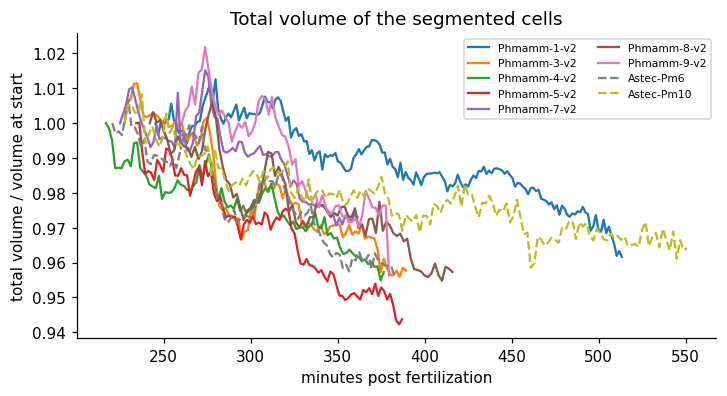

median total volume relative to the median embryo: {'Phmamm-1-v2': 0.92, 'Phmamm-3-v2': 1.06, 'Phmamm-4-v2': 1.07, 'Phmamm-5-v2': 1.0, 'Phmamm-7-v2': 1.18, 'Phmamm-8-v2': 0.83, 'Phmamm-9-v2': 0.93, 'Astec-Pm6': 1.06, 'Astec-Pm10': 0.82}


In [33]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
sizes = {}
for name, lT in embryos:
    total = pd.Series(at.embryo_volume(lT)).sort_index()
    ax.plot(alignment.minutes(name, total.index.values), total / total.iloc[0], ls="-" if name in V2 else "--", label=name)
    sizes[name] = total.median()
ax.set(xlabel="minutes post fertilization", ylabel="total volume / volume at start",
       title="Total volume of the segmented cells")
ax.legend(fontsize=7, ncol=2)
plt.show()
sizes = pd.Series(sizes)
print("median total volume relative to the median embryo:", (sizes / sizes.median()).round(2).to_dict())

### Cell volumes

The volume of a cell is its median over its life. Matched cells differ by a
median of 10% between embryos and 8% between the two sides of an embryo: the
two sides are a little more alike, but the bulk of the difference is the same.
The germ line and the tail-tip cells, the smallest cells of the embryo, vary
the most in relative terms.

In [34]:
volumes = pd.DataFrame({e: tables[e].volume for e in V2})
volume_diffs = at.relative_differences(volumes)
for comparison, d in volume_diffs.groupby("comparison").difference:
    print(f"relative difference of volume, {comparison}: median {d.median():.1%}, mean {d.mean():.1%}, under 10% for {(d < 0.1).mean():.0%} ({len(d)} pairs)")
r_v, n_v = at.side_correlation(volumes)
print(f"correlation of the deviations of the left and right homologues in the same embryo: {r_v:.2f}")
by_tissue = volume_diffs[volume_diffs.comparison == "between embryos"].groupby(
    tissues.reindex(volume_diffs[volume_diffs.comparison == "between embryos"].name).values).difference.median()
print("median relative difference between embryos, by tissue:", by_tissue.round(3).sort_values().to_dict())

relative difference of volume, between embryos: median 10.3%, mean 13.2%, under 10% for 49% (10375 pairs)
relative difference of volume, left/right: median 8.3%, mean 10.8%, under 10% for 58% (1981 pairs)
correlation of the deviations of the left and right homologues in the same embryo: 0.37
median relative difference between embryos, by tissue: {'mixed': 0.079, 'neural': 0.085, 'trunk mesoderm': 0.093, 'endoderm': 0.094, 'muscle': 0.097, 'notochord': 0.104, 'mesenchyme': 0.11, 'epidermis': 0.113, 'germ line': 0.196, 'tail tip': 0.273}


### Unequal divisions

Most divisions split the volume equally, but 26 of 164 give one daughter more
than 1.4 times the volume of the other, and they do so in all the embryos (a
standard deviation of 0.16 on the log<sub>2</sub> ratio). The most unequal
ones are textbook divisions:

- B6.3 gives the germline precursor B7.6, six times smaller than its sister,
  the last of the three unequal cleavages that the centrosome-attracting body
  imposes on the posterior vegetal cells;
- B7.3 gives the small B8.6, the secondary notochord, next to the mesenchyme
  precursor B8.5;
- b8.17 gives the small tail-tip cell b9.33;
- several divisions of the neural plate (a8.25, A8.7, A8.8, A8.16) and of the
  posterior epidermis.

The most unequal of all, B7.7, is also the only one that varies widely
(section 10).

164 divisions seen at least 5 times; 26 are unequal (one daughter more than 1.4 times the volume of the other); the SD of the log2 ratio across embryos is 0.16


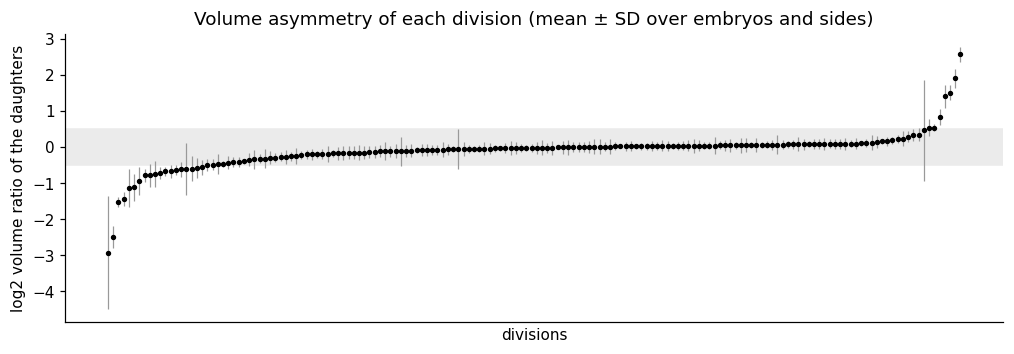

,division,volume ratio,SD of log2 ratio,larger daughter,tissues of the smaller daughter
0,B7.7 -> B8.13 + B8.14,7.58,1.56,B8.14,Mesenchyme
1,B6.3 -> B7.5 + B7.6,5.98,0.20,B7.5,Germ Line
2,b8.17 -> b9.33 + b9.34,5.60,0.31,b9.34,Tail-tip Cells
3,B7.3 -> B8.5 + B8.6,3.78,0.26,B8.5,"2nd Lineage, Notochord"
4,a8.25 -> a9.49 + a9.50,2.87,0.22,a9.49,Anterior Dorsal Neural Plate
5,A8.8 -> A9.15 + A9.16,2.84,0.14,A9.16,Posterior Ventral Neural Plate
6,A8.7 -> A9.13 + A9.14,2.72,0.19,A9.14,Posterior Ventral Neural Plate
7,A8.16 -> A9.31 + A9.32,2.66,0.31,A9.31,Posterior Lateral Neural Plate
8,b9.53 -> b10.105 + b10.106,2.18,0.53,b10.106,Midline Tail Epidermis
9,b8.25 -> b9.49 + b9.50,2.15,0.37,b9.50,Medio-Lateral Tail Epidermis


In [35]:
ratios = at.sister_volume_ratios({e: tables[e] for e in V2})
per_division = ratios.groupby("mother").log2_ratio.agg(["mean", "std", "count"])
per_division = per_division[per_division["count"] >= 5]
unequal = per_division[per_division["mean"].abs() > 0.5]
print(f"{len(per_division)} divisions seen at least 5 times; {len(unequal)} are unequal (one daughter more than 1.4 times "
      f"the volume of the other); the SD of the log2 ratio across embryos is {per_division['std'].median():.2f}")
top = per_division.reindex(per_division["mean"].abs().sort_values(ascending=False).index).head(12)
listing = pd.DataFrame({
    "division": [f"{at.conklin(m + '_')} -> {' + '.join(at.conklin(d) for d in at.daughters(m + '_'))}" for m in top.index],
    "volume ratio": [2 ** abs(v) for v in top["mean"]],
    "SD of log2 ratio": top["std"].values,
    "larger daughter": [at.conklin(at.daughters(m + "_")[0 if v > 0 else 1]) for m, v in zip(top.index, top["mean"])],
    "tissues of the smaller daughter": [", ".join(sorted(fates.get(at.daughters(m + "_")[1 if v > 0 else 0], []))) for m, v in zip(top.index, top["mean"])],
})
fig, ax = plt.subplots(figsize=(11, 3.4))
s = per_division.sort_values("mean")
ax.errorbar(range(len(s)), s["mean"], yerr=s["std"], fmt="o", ms=2.5, lw=0.8, color="k", ecolor="0.6")
ax.axhspan(-0.5, 0.5, color="0.92")
ax.set(xticks=[], xlabel="divisions", ylabel="log2 volume ratio of the daughters",
       title="Volume asymmetry of each division (mean ± SD over embryos and sides)")
plt.show()
listing.round(2)

Within a generation, larger cells divide only slightly sooner (rank
correlations from +0.1 to -0.4, depending on the embryo and the
generation). But in unequal divisions, the smaller daughter
divides later in 83% of the cases, by 9 minutes in median, as Guignard et al.
observed.

In [36]:
rows = []
for e in V2:
    t = tables[e].assign(cycle=cycles[e])
    for g in (8, 9):
        s = t[(t.gen == g) & t.cycle.notna()]
        if len(s) > 20:
            rows.append({"embryo": e, "generation": g, "cells": len(s), "rho": spearmanr(s.volume, s.cycle)[0]})
correlations = pd.DataFrame(rows)
print("Spearman correlation between the volume of a cell and its cycle length, within a generation:")
print(correlations.groupby("generation").rho.agg(["median", "min", "max", "count"]).round(2))
sisters_cycle = []
for m in unequal.index:
    odd, even = at.daughters(m + "_")
    for side in "_*":
        o, ev = odd[:-1] + side, even[:-1] + side
        if o in cycles.index and ev in cycles.index:
            diff = (cycles.loc[o] - cycles.loc[ev]).dropna()
            if len(diff):
                smaller_is_odd = per_division.at[m, "mean"] < 0
                sisters_cycle.append((diff.median() if smaller_is_odd else -diff.median()))
print(f"unequal divisions with both cycles measured: {len(sisters_cycle)}; the smaller daughter has the longer cycle in "
      f"{np.mean(np.array(sisters_cycle) > 0):.0%} of them (median difference {np.median(sisters_cycle):+.0f} min)")

Spearman correlation between the volume of a cell and its cycle length, within a generation:
            median   min   max  count
generation                           
8            -0.12 -0.27  0.09      6
9            -0.24 -0.37 -0.11      2
unequal divisions with both cycles measured: 42; the smaller daughter has the longer cycle in 83% of them (median difference +9 min)


## 5. Shapes and orientations of the divisions

### Cell shape

The sphericity compares the surface of a cell with that of a sphere of the
same volume, and the elongation is the ratio of the longest to the shortest
axis of the cell, from the principal values of its shape. The notochord cells
are the most elongated (2.5 times longer than wide at generation 9), the
epidermis the least. The sphericity of a cell is very reproducible (3%
between embryos); the elongation less so (11%).

In [37]:
shape = pd.concat([tables[e].assign(embryo=e) for e in V2])
shape = shape[shape.tissue != "unknown"]
print("median sphericity and elongation of the cells of generation 9, by tissue:")
print(shape[shape.gen == 9].groupby("tissue")[["sphericity", "elongation", "exterior"]].median().round(2).sort_values("elongation"))
elongation = pd.DataFrame({e: tables[e].elongation for e in V2})
sphericity_ = pd.DataFrame({e: tables[e].sphericity for e in V2})
for label, values in (("sphericity", sphericity_), ("elongation", elongation)):
    d = at.relative_differences(values)
    print(f"{label}: relative difference between embryos median {d[d.comparison == 'between embryos'].difference.median():.1%}, "
          f"left/right {d[d.comparison == 'left/right'].difference.median():.1%}")

median sphericity and elongation of the cells of generation 9, by tissue:
                sphericity  elongation  exterior
tissue                                          
epidermis             0.83        1.62      0.28
neural                0.81        1.81      0.21
trunk mesoderm        0.83        1.83      0.00
mesenchyme            0.78        1.90      0.00
muscle                0.82        1.95      0.13
endoderm              0.77        2.04      0.01
tail tip              0.79        2.46      0.38
notochord             0.76        2.51      0.04
sphericity: relative difference between embryos median 3.0%, left/right 1.8%
elongation: relative difference between embryos median 10.6%, left/right 7.4%


### Hertwig's rule

Hertwig (1884) proposed that cells divide along their longest axis. Here, the
axis of a division is the vector between the two daughters just after it,
and the long axis of the mother is measured 6 minutes before, before it rounds
up. The two are aligned in most divisions (median |cos| 0.90, against 0.5 for
random axes), as much in unequal divisions as in equal ones.

In [38]:
divisions = {e: at.division_table(embryos[e], tables[e], alignment.frame_minutes(e)) for e in V2}
hertwig = pd.concat([d.assign(embryo=e) for e, d in divisions.items()])
hertwig["unequal"] = [abs(per_division["mean"].get(m[:-1], 0)) > 0.5 for m in hertwig.index]
rng = np.random.default_rng(0)
random_axes = rng.normal(size=(100000, 3))
random_cos = np.abs(random_axes[:, 0]) / np.linalg.norm(random_axes, axis=1)
print(f"{len(hertwig)} divisions; |cos| between the division and the longest axis of the mother: median {hertwig.hertwig.median():.2f} "
      f"(random: {np.median(random_cos):.2f}); within 30 degrees for {(hertwig.hertwig > np.cos(np.radians(30))).mean():.0%} "
      f"(random: {(random_cos > np.cos(np.radians(30))).mean():.0%})")
for label, s in hertwig.groupby("unequal").hertwig:
    print(f"  {'unequal' if label else 'equal'} divisions: median {s.median():.2f} ({len(s)})")
print("  p (Mann-Whitney):", f"{mannwhitneyu(hertwig[hertwig.unequal].hertwig, hertwig[~hertwig.unequal].hertwig).pvalue:.2g}")

1855 divisions; |cos| between the division and the longest axis of the mother: median 0.90 (random: 0.50); within 30 degrees for 55% (random: 13%)
  equal divisions: median 0.91 (1532)
  unequal divisions: median 0.90 (323)
  p (Mann-Whitney): 0.67


### Reproducibility of the orientations

To compare orientations across embryos, each embryo is registered onto the
reference at the time of each division (rotation, scaling and translation
fitted on all their common cells), and the vector from one named daughter to
the other is rotated into the reference. Because the daughters are named, the
direction counts, not only the axis.

Divisions are oriented the same way in all the embryos to a median of 12
degrees, a little less precisely at each generation. Unequal divisions are
more precisely oriented than equal ones, as Biasuz et al. found for the
asymmetric divisions. The few variable ones (A7.2, B9.9, B9.10...) are
candidates for the bimodal orientations that they describe.

In [39]:
REGISTRATION = at.REFERENCE
rotations, rows = {}, []
for e in V2:
    for mother_name, d in divisions[e].iterrows():
        t_ref = at.frame_at(alignment, REGISTRATION, alignment.to_reference(e, d.frame))
        if t_ref is None:
            continue
        key = (e, d.frame)
        if key not in rotations:
            rotations[key] = at.rotation_to(embryos, e, int(d.frame), REGISTRATION, t_ref)
        v = rotations[key] @ np.array([d.x, d.y, d.z])
        rows.append({"mother": mother_name, "embryo": e, "v": v / np.linalg.norm(v)})
oriented = pd.DataFrame(rows)
angles = []
for m, group in oriented.groupby("mother"):
    if len(group) < 4:
        continue
    vectors = np.stack(group.v.values)
    mean = vectors.mean(axis=0)
    mean /= np.linalg.norm(mean)
    deviation = np.degrees(np.arccos(np.clip(vectors @ mean, -1, 1)))
    angles.append({"mother": m, "median angle": np.median(deviation), "inverted": (deviation > 90).mean(), "embryos": len(group),
                   "unequal": abs(per_division["mean"].get(m[:-1], 0)) > 0.5, "gen": at.parse_name(m)[1]})
angles = pd.DataFrame(angles).set_index("mother")
print(f"{len(angles)} divisions seen in at least 4 embryos, after registration onto {REGISTRATION}:")
print(f"  median angle to the mean orientation: {angles['median angle'].median():.0f} degrees; "
      f"over 45 degrees for {(angles['median angle'] > 45).mean():.0%} of the divisions")
print("  by generation of the mother:", angles.groupby("gen")["median angle"].median().round(0).to_dict())
print("  equal vs unequal divisions:", angles.groupby("unequal")["median angle"].median().round(0).to_dict(),
      f"p = {mannwhitneyu(angles[angles.unequal]['median angle'], angles[~angles.unequal]['median angle']).pvalue:.2g}")
print("  most variable:", {at.conklin(m): round(v) for m, v in angles["median angle"].sort_values().tail(8).items()})

260 divisions seen in at least 4 embryos, after registration onto Phmamm-8-v2:
  median angle to the mean orientation: 12 degrees; over 45 degrees for 0% of the divisions
  by generation of the mother: {7: 10.0, 8: 12.0, 9: 13.0}
  equal vs unequal divisions: {False: 12.0, True: 10.0} p = 0.0046
  most variable: {'B9.10*': 30, 'a8.31': 31, 'a9.44*': 33, 'B9.9*': 35, 'b9.50': 36, 'a9.53': 37, 'B9.10': 40, 'A7.2*': 49}


## 6. Positions

At each reference time, every pair of embryos is registered on their common
cells (rotation, scaling and translation, `at.similarity_fit`), and each
embryo with its own mirror image, the names of the two sides swapped. The
distance between matched cells is expressed in typical cell radii (the radius
of the embryo divided by the cube root of its number of cells), a unit that
shrinks as the cells divide.

At the 64-cell stage, matched cells are a third of a cell radius apart between
embryos and a quarter between the two sides. Both distances grow during
gastrulation, to 0.85 cell radius at the start of neurulation (400 minutes)
and one cell radius at the tailbud between the two sides: the embryos keep the
same arrangement of cells, but each cell drifts a little more around its
place. At 320 minutes, the germ line, internalised with the endoderm, is the
least precisely placed tissue.

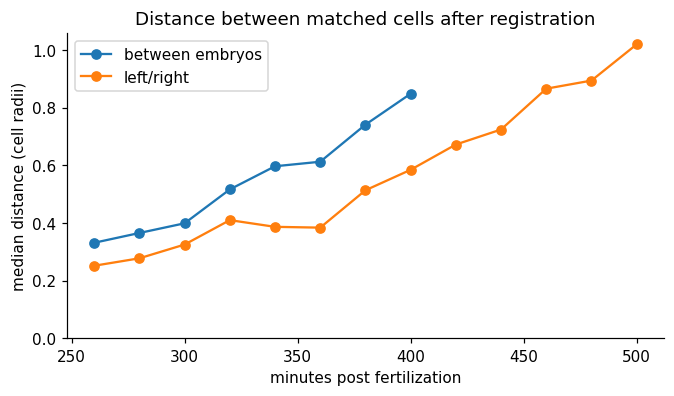

at 320.0 min, median distance between embryos by tissue (cell radii): {'mixed': 0.35, 'mesenchyme': 0.42, 'notochord': 0.45, 'neural': 0.46, 'muscle': 0.52, 'endoderm': 0.54, 'epidermis': 0.55, 'trunk mesoderm': 0.58, 'germ line': 0.78}


In [40]:
TIMES = np.arange(10, 131, 10)  # reference time points: 260 to 500 minutes post fertilization
position_table = pd.concat([at.position_deviations(embryos, alignment, tau, V2).assign(minutes=alignment.minutes(at.REFERENCE, tau))
                            for tau in TIMES])
summary_positions = position_table.groupby(["minutes", "comparison"]).distance.median().unstack()
fig, ax = plt.subplots(figsize=(7, 3.6))
for comparison in summary_positions:
    ax.plot(summary_positions.index, summary_positions[comparison], marker="o", label=comparison)
ax.set(xlabel="minutes post fertilization", ylabel="median distance (cell radii)", ylim=(0, None),
       title="Distance between matched cells after registration")
ax.legend()
plt.show()
mid = position_table[(position_table.minutes == alignment.minutes(at.REFERENCE, 40)) & (position_table.comparison == "between embryos")]
print("at", alignment.minutes(at.REFERENCE, 40), "min, median distance between embryos by tissue (cell radii):",
      mid.groupby(tissues.reindex(mid.name).values).distance.median().round(2).sort_values().to_dict())

## 7. Contacts

### Neighbourhoods

The neighbourhood of a cell is the fraction of its surface in contact with
each neighbour. Two neighbourhoods are compared with the distance of Biasuz et
al.: the fraction of the surface of the cell in contact with different cells.
When a neighbour has divided in one embryo and not yet in the other, its
daughters are merged into it (their "virtual common neighbourhood"). Cells
born less than 8 minutes before are left out, while their contacts settle.

Cells have 5 to 6 neighbours (contacts above 5% of their surface), a few
less at the tailbud. The same cell in two embryos shares 87% of its contact
surface at the 64-cell stage and 71% at the start of neurulation (400
minutes); the two sides of an embryo are slightly more alike; two sisters,
which sit side by side, share only about 40%. These are the
"20% versus 60%" of Biasuz et al., and the drift follows that of the
positions.

mean number of neighbours (over 5% of the surface): {260: np.float64(5.1), 280: np.float64(5.4), 300: np.float64(5.5), 320: np.float64(5.7), 340: np.float64(5.6), 360: np.float64(5.6), 380: np.float64(5.7), 400: np.float64(6.0), 420: np.float64(6.1), 440: np.float64(5.9), 460: np.float64(5.5), 480: np.float64(4.8), 500: np.float64(4.7)}


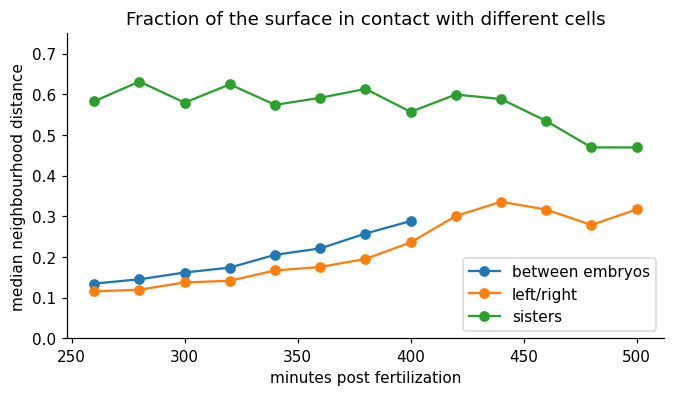

minutes,260.0,280.0,300.0,320.0,340.0,360.0,380.0,400.0,420.0,440.0,460.0,480.0,500.0
comparison,,,,,,,,,,,,,
between embryos,0.13,0.14,0.16,0.17,0.21,0.22,0.26,0.29,NaN,NaN,NaN,NaN,NaN
left/right,0.12,0.12,0.14,0.14,0.17,0.18,0.19,0.24,0.3,0.34,0.32,0.28,0.32
sisters,0.58,0.63,0.58,0.62,0.57,0.59,0.61,0.56,0.6,0.59,0.53,0.47,0.47


In [41]:
neighbourhoods = {tau: at.neighbourhoods_at(embryos, alignment, tau, V2) for tau in TIMES}
neighbour_table = pd.concat([at.neighbourhood_comparisons(nb).assign(minutes=alignment.minutes(at.REFERENCE, tau))
                             for tau, nb in neighbourhoods.items()])
n_neighbours = {alignment.minutes(at.REFERENCE, tau): np.mean([at.count_neighbours(v) for cells in nb.values() for v in cells.values()])
                for tau, nb in neighbourhoods.items()}
print("mean number of neighbours (over 5% of the surface):", {round(k): round(v, 1) for k, v in n_neighbours.items()})
summary_neighbours = neighbour_table.groupby(["minutes", "comparison"]).distance.median().unstack()
fig, ax = plt.subplots(figsize=(7, 3.6))
for comparison in ["between embryos", "left/right", "sisters"]:
    ax.plot(summary_neighbours.index, summary_neighbours[comparison], marker="o", label=comparison)
ax.set(xlabel="minutes post fertilization", ylabel="median neighbourhood distance", ylim=(0, 0.75),
       title="Fraction of the surface in contact with different cells")
ax.legend()
plt.show()
summary_neighbours.round(2).T

### Over the whole life of the cells

Guignard et al. compared the neighbours of matched cells over their lives:
more than 80% of the cells shared at least 80% of their neighbours, and for
80% of the cells the contact areas with shared neighbours changed by less than
20% on average. With neighbourhoods averaged over the life of each cell (cells
born and divided in both embryos), 75% of the cells share at least 80% of
their neighbours, and 74% have less than 20% of their surface in contact with
different cells. The change of each shared contact is larger: it is under 20%
for only 45% of the cells, because small contacts vary a lot, as the next
figure shows. The exact definitions of the paper are not reproduced here, so
the comparison is qualitative.

In [42]:
life = at.life_comparisons(embryos, alignment, V2)
per_cell_life = life.groupby("name")[["distance", "shared", "change"]].median()
print(f"{life.name.nunique()} cells born and divided in at least two embryos, {len(life)} comparisons of their neighbourhoods "
      f"averaged over their lives:")
print(f"  share at least 80% of their neighbours: {(per_cell_life.shared >= 0.8).mean():.0%} of the cells")
print(f"  contacts with shared neighbours change by less than 20% on average: {(per_cell_life.change < 0.2).mean():.0%} of the cells")
print(f"  less than 20% of the surface in contact with different cells: {(per_cell_life.distance < 0.2).mean():.0%} of the cells "
      f"(median {per_cell_life.distance.median():.2f})")

311 cells born and divided in at least two embryos, 3268 comparisons of their neighbourhoods averaged over their lives:
  share at least 80% of their neighbours: 75% of the cells
  contacts with shared neighbours change by less than 20% on average: 45% of the cells
  less than 20% of the surface in contact with different cells: 74% of the cells (median 0.15)


### Large contacts are stable, small ones come and go

At 320 minutes, during gastrulation, every contact between two cells is
followed in all the embryos. The variability of a contact depends on its size:
contacts above 10% of the surface of a cell exist in all the embryos and vary
by 10 to 20%; contacts under 2% exist in all the embryos in only 9% of the
cases, and vary by more than their own size. Inductions that depend on the area of
contact, as Guignard et al. showed, can rely on the large contacts.

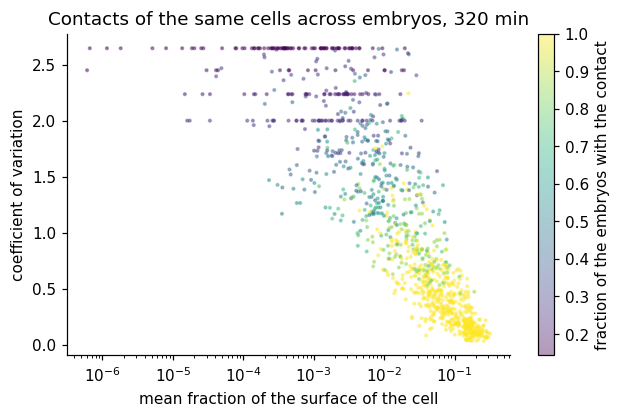

,contacts,present_in_all,coefficient of variation
mean,,,
"(0.0, 0.02]",513,0.09,1.85
"(0.02, 0.05]",202,0.59,0.71
"(0.05, 0.1]",158,0.82,0.43
"(0.1, 0.2]",173,0.98,0.19
"(0.2, 0.4]",42,1.00,0.11


In [43]:
variability = at.contact_variability(neighbourhoods[40])
variability = variability[variability.neighbour != "outside"]
bins = pd.cut(variability["mean"], [0, 0.02, 0.05, 0.1, 0.2, 0.4, 1])
by_size = variability.groupby(bins, observed=True).agg(contacts=("mean", "size"),
                                                       present_in_all=("present", lambda x: (x == 1).mean()))
by_size["coefficient of variation"] = variability.groupby(bins, observed=True).apply(lambda g: (g.sd / g["mean"]).median())
fig, ax = plt.subplots(figsize=(6.5, 3.8))
points = ax.scatter(variability["mean"], variability.sd / variability["mean"], s=3, alpha=0.4, c=variability.present,
                    cmap="viridis")
plt.colorbar(points, label="fraction of the embryos with the contact")
ax.set(xscale="log", xlabel="mean fraction of the surface of the cell", ylabel="coefficient of variation",
       title=f"Contacts of the same cells across embryos, {alignment.minutes(at.REFERENCE, 40):.0f} min")
plt.show()
by_size.round(2)

### Gastrulation

The fraction of the surface of a tissue that faces the outside of the embryo
falls when it moves inside. In the aligned time, the curves of the seven
embryos superimpose: the endoderm and the germ line go in first, then the
mesenchyme, the trunk mesoderm and the notochord (by 300 minutes), and the
muscle (by 380 minutes); the neural plate closes into the neural tube at the
end of the longest movie, and the epidermis stays outside.

The shift of each curve that best matches the median curve measures the
timing of each tissue in each embryo: the standard deviations are 1 to 4.5
minutes, as precise as the divisions, except for the small germ line. The
alignment was fitted on the divisions only, so morphogenesis follows the same
clock as the cell cycles.
Two exceptions: the germ line of Phmamm-3-v2 goes in 20 minutes early, and
the muscle of Phmamm-1-v2 10 minutes early.

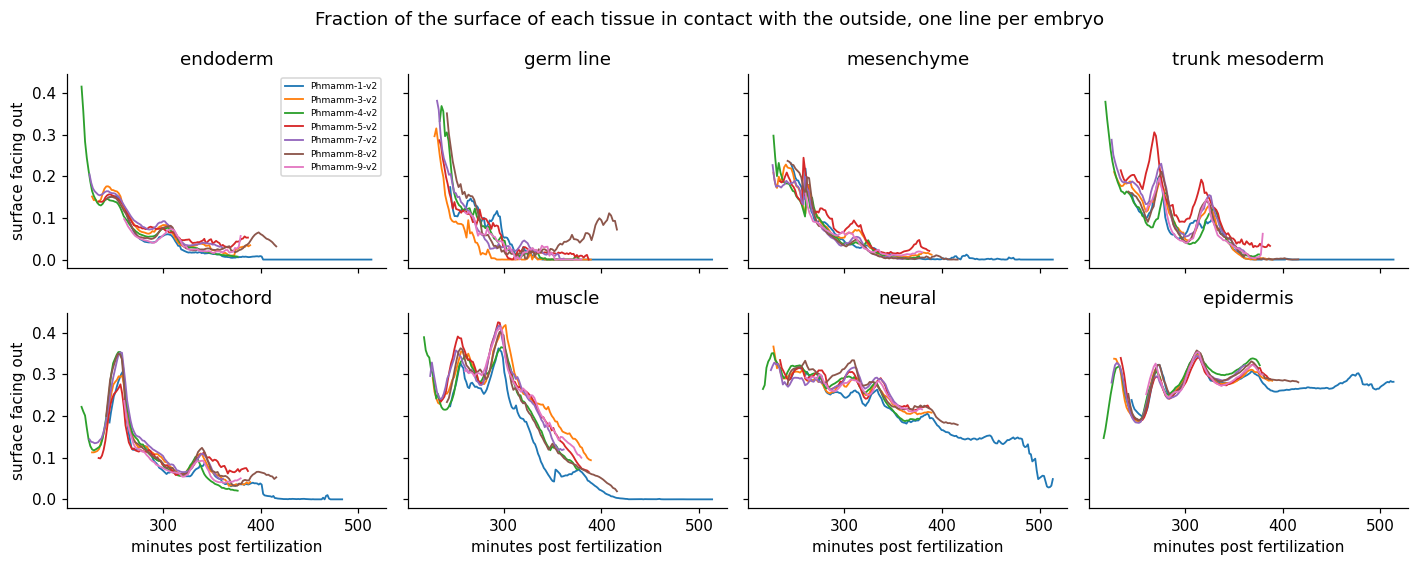

shift of the curve of each embryo that best matches the median curve (minutes, positive: late):


,Phmamm-1-v2,Phmamm-3-v2,Phmamm-4-v2,Phmamm-5-v2,Phmamm-7-v2,Phmamm-8-v2,Phmamm-9-v2,SD
endoderm,-1.5,0.5,-1.5,3.0,3.0,0.0,-1.0,2.0
germ line,10.0,-19.5,2.0,6.0,-4.0,0.5,0.0,9.4
mesenchyme,0.5,2.0,0.5,11.0,-0.5,0.5,-3.5,4.5
trunk mesoderm,-2.5,0.5,5.0,-4.0,0.5,0.5,-2.0,2.9
notochord,0.0,0.5,0.5,-2.0,3.0,0.0,-1.5,1.6
muscle,-10.0,4.0,-0.5,-0.5,-1.0,-1.5,-0.5,4.2
neural,-3.5,0.0,-2.5,2.0,2.0,-0.5,2.0,2.3
epidermis,1.0,-0.5,-0.5,1.0,0.0,1.0,-1.0,0.9


In [44]:
exterior = at.exterior_by_tissue(embryos, alignment, tissues, V2)
shown_tissues = ["endoderm", "germ line", "mesenchyme", "trunk mesoderm", "notochord", "muscle", "neural", "epidermis"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2), sharex=True, sharey=True)
shifts = {}
for ax, tissue in zip(axes.flat, shown_tissues):
    curves = {}
    for e in V2:
        s = exterior[(exterior.embryo == e) & (exterior.tissue == tissue)].sort_values("minutes")
        ax.plot(s.minutes, s.exterior, lw=1.2, label=e)
        curves[e] = s.set_index("minutes").exterior
    shifts[tissue] = at.curve_shifts(curves)
    ax.set_title(tissue)
for ax in axes[:, 0]:
    ax.set_ylabel("surface facing out")
for ax in axes[1]:
    ax.set_xlabel("minutes post fertilization")
axes[0, 0].legend(fontsize=6)
plt.suptitle("Fraction of the surface of each tissue in contact with the outside, one line per embryo")
plt.tight_layout()
plt.show()
shifts = pd.DataFrame(shifts)
print("shift of the curve of each embryo that best matches the median curve (minutes, positive: late):")
shifts.T.assign(SD=shifts.std()).round(1)

## 8. Lineage trees

### The tree edit distance needs the alignment

`LineageTreeManager.cross_lineage_edit_distance` compares the lineages of two
cells of two embryos with the unordered tree edit distance (UTED): the cost of
the edits that turn one tree into the other, where each cell weighs its
length. Before comparing, the manager multiplies the lengths of the cells by
the time resolution of their embryo; `at.set_time_resolutions` sets it to the
duration of a time point in reference minutes, which puts the linear
alignment into the distance. (The resolution is stored as a whole number of
tenths, so the minutes are multiplied by 100; the factor cancels out in
normalised distances.)

The lineages of the cells alive at 270 minutes are followed until 354
minutes, the last time covered by all seven movies. Without the alignment,
with the same number of time points in every embryo, the distance between two
embryos follows the difference of their paces (rank correlation 0.93); with
it, the pace no longer matters (-0.08), and the median distance halves.

In [45]:
START, END = 15, 57  # reference time points: 270 and 354 minutes post fertilization
for e in V2 + V1:  # without the alignment: every time point counts the same in every embryo
    embryos[e].time_resolution = alignment.interval * at.SCALE
naive = at.lineage_distances(embryos, alignment, START, END, V2, sides=False, frames_only=True)
at.set_time_resolutions(embryos, alignment, V2 + V1)
lineages = at.lineage_distances(embryos, alignment, START, END, V2)
print(f"lineages of the {lineages.name.nunique()} cells alive at {alignment.minutes(at.REFERENCE, START):.0f} min, "
      f"followed until {alignment.minutes(at.REFERENCE, END):.0f} min")
pace = {e: alignment.slope[e] for e in V2}
for label, table_ in (("without the alignment", naive), ("with the alignment", lineages[lineages.comparison == "between embryos"])):
    pace_gap = np.abs(table_.embryo.map(pace) - table_.other.map(pace))
    per_pair = table_.groupby(["embryo", "other"]).distance.median()
    gap = per_pair.index.map(lambda p: abs(pace[p[0]] - pace[p[1]]))
    print(f"  {label}: median distance between embryos {table_.distance.median():.3f}; rank correlation of the "
          f"distance of two embryos with the difference of their paces {spearmanr(gap, per_pair.values)[0]:.2f}")

lineages of the 78 cells alive at 270 min, followed until 354 min
  without the alignment: median distance between embryos 0.165; rank correlation of the distance of two embryos with the difference of their paces 0.93
  with the alignment: median distance between embryos 0.090; rank correlation of the distance of two embryos with the difference of their paces -0.08


### How alike are the lineages?

The lineages of matched cells differ by a median normalised UTED of 9% between
embryos and 7% between the two sides of an embryo, the "less than 10%" of
Guignard et al. The variable lineages are vegetal: the notochord, the
mesenchyme and the trunk mesoderm (B8.5, B8.6, A8.6, A8.13, A8.14, B7.7), while
the epidermis and the germ line are the most reproducible. The distances
between embryos are all close; Phmamm-3 and 4, and Phmamm-5 and 7, are more
alike than the other pairs, perhaps because they were imaged on the same days,
which the files do not record.

between embryos: median 0.090, mean 0.129, under 10% for 54% (1557 comparisons)
left/right: median 0.072, mean 0.108, under 10% for 61% (259 comparisons)
median distance between embryos by tissue of the lineage: {'germ line': 0.012, 'epidermis': 0.077, 'muscle': 0.08, 'neural': 0.098, 'endoderm': 0.13, 'mixed': 0.13, 'trunk mesoderm': 0.168, 'mesenchyme': 0.176, 'notochord': 0.192}
most variable lineages: {'A8.13': 0.202, 'B7.7*': 0.206, 'B8.6': 0.234, 'A8.6': 0.26, 'B8.5*': 0.261, 'A8.14': 0.268, 'b8.18*': 0.284, 'B8.6*': 0.292}


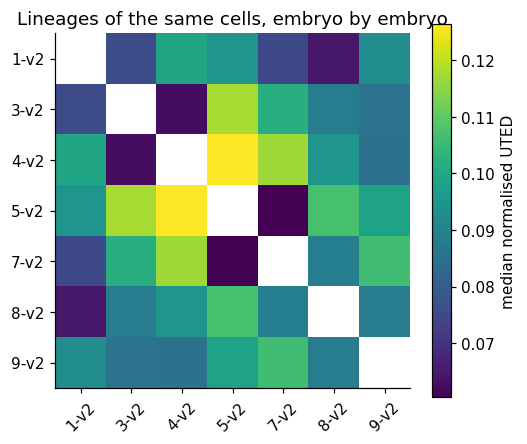

In [46]:
between = lineages[lineages.comparison == "between embryos"]
sides = lineages[lineages.comparison == "left/right"]
for label, d in (("between embryos", between.distance), ("left/right", sides.distance)):
    print(f"{label}: median {d.median():.3f}, mean {d.mean():.3f}, under 10% for {(d < 0.1).mean():.0%} ({len(d)} comparisons)")
per_lineage = between.groupby("name").distance.median()
per_lineage_tissue = per_lineage.groupby(tissues.reindex(per_lineage.index).values).median()
print("median distance between embryos by tissue of the lineage:", per_lineage_tissue.round(3).sort_values().to_dict())
print("most variable lineages:", {at.conklin(n): round(v, 3) for n, v in per_lineage.sort_values().tail(8).items()})
matrix = between.groupby(["embryo", "other"]).distance.median().unstack()
full = matrix.combine_first(matrix.T)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
image = ax.imshow(full.loc[V2, V2].values, cmap="viridis")
ax.set_xticks(range(len(V2)), [e.replace("Phmamm-", "") for e in V2], rotation=45)
ax.set_yticks(range(len(V2)), [e.replace("Phmamm-", "") for e in V2])
plt.colorbar(image, label="median normalised UTED")
ax.set_title("Lineages of the same cells, embryo by embryo")
plt.show()

### Where do sisters part ways?

Guignard et al. compared the lineages of the two daughters of each division:
divisions whose daughters make different lineages were mostly those where the
fate is restricted. Here, in Phmamm-1-v2, the lineages of the two daughters
of each division are followed for two hours. Divisions whose daughters make
different tissues are more often asymmetric than the others (75% more than
10% apart, against 44%), and an AUC of 0.69 says that a division with a
change of tissue usually has more divergent daughters than one without. With the finer territories of the files
(the lateral and the medio-lateral tail epidermis, for instance), the link
disappears: the lineage marks the restriction to a tissue, not the
territories within it.

Phmamm-1-v2: 274 divisions from 257 to 392 min, lineages of the daughters followed for 120 min; 125 (46%) more than 10% apart
  daughters whose tissues differ: 12 divisions, 75% more than 10% apart (others: 44%); AUC 0.69
  daughters whose territories differ: 36 divisions, 44% more than 10% apart (others: 46%); AUC 0.49
  most asymmetric: {'A8.7*': 0.48, 'a9.37': 0.5, 'b9.50*': 0.57, 'a9.60*': 0.57, 'b9.40*': 0.64, 'B7.7*': 0.65, 'a8.25*': 0.7, 'a8.25': 0.8, 'b9.48*': 0.83, 'B7.7': 0.89}


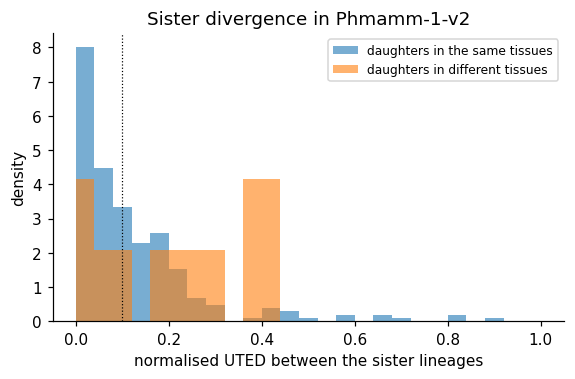

In [47]:
WINDOW = 120  # minutes after the division
sisters_P1 = at.sister_divergence(embryos, alignment, "Phmamm-1-v2", duration=WINDOW)
sisters_P1["tissues differ"] = [at.restricts_fate(fates, m) for m in sisters_P1.index]
sisters_P1["territories differ"] = [at.restricts_fate(fates, m, coarse=False) for m in sisters_P1.index]
sisters_P1 = sisters_P1.dropna(subset=["tissues differ"])
asymmetric = sisters_P1.distance > 0.1
print(f"Phmamm-1-v2: {len(sisters_P1)} divisions from {sisters_P1.minutes.min():.0f} to {sisters_P1.minutes.max():.0f} min, "
      f"lineages of the daughters followed for {WINDOW} min; {asymmetric.sum()} ({asymmetric.mean():.0%}) more than 10% apart")
for column in ("tissues differ", "territories differ"):
    restricted = sisters_P1[column].astype(bool)
    auc = (mannwhitneyu(sisters_P1.distance[restricted], sisters_P1.distance[~restricted]).statistic
           / (restricted.sum() * (~restricted).sum()))
    print(f"  daughters whose {column.split()[0]} differ: {restricted.sum()} divisions, {(asymmetric & restricted).sum() / restricted.sum():.0%} "
          f"more than 10% apart (others: {(asymmetric & ~restricted).sum() / (~restricted).sum():.0%}); AUC {auc:.2f}")
print("  most asymmetric:", {at.conklin(m): round(d, 2) for m, d in sisters_P1.distance.sort_values().tail(10).items()})
restricted = sisters_P1["tissues differ"].astype(bool)
fig, ax = plt.subplots(figsize=(6, 3.4))
bins = np.linspace(0, 1, 26)
ax.hist(sisters_P1.distance[~restricted], bins=bins, alpha=0.6, density=True, label="daughters in the same tissues")
ax.hist(sisters_P1.distance[restricted], bins=bins, alpha=0.6, density=True, label="daughters in different tissues")
ax.axvline(0.1, color="k", lw=0.8, ls=":")
ax.set(xlabel="normalised UTED between the sister lineages", ylabel="density", title="Sister divergence in Phmamm-1-v2")
ax.legend(fontsize=8)
plt.show()

### Are the same divisions asymmetric in all the embryos?

With one-hour windows, the sister distances can be measured in the seven
embryos. Three quarters of the divisions are called the same way (asymmetric
or not) in at least 80% of the observations, and the two sides of an embryo
agree (rank correlation 0.61). Pooled over the embryos, 47% of the divisions
whose daughters make different tissues are more than 10% apart, against 17%
of the others. The divisions that are always asymmetric include A7.6, b7.9
and b7.10, which are also among the programmed sister asynchronies of
section 3.

In [48]:
DURATION = 60  # minutes after the division
divergence = pd.concat([at.sister_divergence(embryos, alignment, e, duration=DURATION) for e in V2])
divergence["division"] = [m[:-1] for m in divergence.index]
divergence["tissues differ"] = [at.restricts_fate(fates, m) for m in divergence.index]
calls = divergence.groupby("division").distance.agg(["median", "count", lambda x: (x > 0.1).mean()])
calls.columns = ["median", "observations", "asymmetric"]
calls = calls[calls.observations >= 6]
consistent = ((calls.asymmetric <= 0.2) | (calls.asymmetric >= 0.8)).mean()
left = divergence[divergence.index.str.endswith("_")].reset_index().set_index(["division", "embryo"]).distance
right = divergence[divergence.index.str.endswith("*")].reset_index().set_index(["division", "embryo"]).distance
both = pd.concat([left, right], axis=1, keys=["left", "right"]).dropna()
known = divergence.dropna(subset=["tissues differ"])
restricted = known["tissues differ"].astype(bool)
auc = mannwhitneyu(known.distance[restricted], known.distance[~restricted]).statistic / (restricted.sum() * (~restricted).sum())
print(f"{len(divergence)} sister pairs in the 7 embryos, lineages followed for {DURATION} min; "
      f"{len(calls)} divisions seen at least 6 times (sides and embryos):")
print(f"  called asymmetric (>10%) in at least 80% or at most 20% of the observations: {consistent:.0%} of the divisions")
print(f"  rank correlation of the sister distances of the two sides of the same embryo: {spearmanr(both.left, both.right)[0]:.2f}")
print(f"  daughters in different tissues: {(known.distance[restricted] > 0.1).mean():.0%} more than 10% apart, "
      f"others {(known.distance[~restricted] > 0.1).mean():.0%}; AUC {auc:.2f}")
print("  always asymmetric:", [at.conklin(d + "_") for d in calls[calls.asymmetric >= 0.8].sort_values("median").index])

1016 sister pairs in the 7 embryos, lineages followed for 60 min; 71 divisions seen at least 6 times (sides and embryos):
  called asymmetric (>10%) in at least 80% or at most 20% of the observations: 73% of the divisions
  rank correlation of the sister distances of the two sides of the same embryo: 0.61
  daughters in different tissues: 47% more than 10% apart, others 17%; AUC 0.66
  always asymmetric: ['b8.27', 'A8.7', 'b7.10', 'b8.21', 'b8.25', 'b7.9', 'A7.6']


### Adding the volumes to the tree distance

The `simple` style of the UTED compares timing only. `at.SimpleWithVolume`
also compares the volumes of matched cells: matching two cells of lengths
*l*<sub>1</sub> and *l*<sub>2</sub> costs |*l*<sub>1</sub> - *l*<sub>2</sub>|
plus a quarter of min(*l*<sub>1</sub>, *l*<sub>2</sub>) for each two-fold
difference of volume. With it, the sister distance rises most for the unequal
divisions (rank correlation of 0.57 between the gain and the volume ratio):
B7.3, b8.17, A8.16, A8.7 and B7.7 come forward. A lineage distance can carry
geometry as well as timing.

In [49]:
for e in V2:
    at.add_log_volume(embryos[e])
at.SimpleWithVolume.weight = 0.25  # a two-fold difference of volume costs a quarter of the life of the cells
with_volume = at.sister_divergence(embryos, alignment, "Phmamm-1-v2", duration=WINDOW, style=at.SimpleWithVolume)
compare = pd.DataFrame({"timing": sisters_P1.distance, "timing and volume": with_volume.distance}).dropna()
compare["gain"] = compare["timing and volume"] - compare["timing"]
compare["volume ratio"] = [2 ** abs(per_division["mean"].get(m[:-1], np.nan)) for m in compare.index]
print(f"more than 10% apart: timing alone {(compare.timing > 0.1).sum()}, timing and volume {(compare['timing and volume'] > 0.1).sum()} "
      f"of {len(compare)} divisions")
print(f"rank correlation between the gain and the volume ratio of the daughters: {spearmanr(compare.gain, compare['volume ratio'], nan_policy='omit')[0]:.2f}")
print("divisions that the volumes bring forward most:")
compare.sort_values("gain").tail(8).rename(index=at.conklin).round(2)

more than 10% apart: timing alone 125, timing and volume 162 of 274 divisions
rank correlation between the gain and the volume ratio of the daughters: 0.57
divisions that the volumes bring forward most:


,timing,timing and volume,gain,volume ratio
A8.7,0.38,0.68,0.30,2.72
B7.7*,0.65,0.96,0.31,7.58
A8.16*,0.29,0.60,0.31,2.66
B7.7,0.89,1.25,0.37,7.58
B7.3,0.26,0.63,0.37,3.78
b8.17*,0.00,0.47,0.47,5.60
b8.17,0.24,0.71,0.47,5.60
B7.3*,0.10,0.57,0.47,3.78


## 9. Which cells vary?

Each measure gives a variability per cell. Their rank correlations show two
independent groups: the timing measures (cycle length, division time, and the
UTED, which is built on them) on one side, and the geometric ones (position,
neighbourhood, and to a lesser extent volume) on the other. A cell whose
divisions are imprecise is not more variable in its position or its contacts.

By tissue, the epidermis and the neural plate are the most precise in time,
the notochord, the trunk mesoderm and the mesenchyme the least. The germ line,
small cells that move inside with the endoderm, varies most in volume and
contacts, and the mesenchyme in position.

rank correlations between the variability measures of the cells:
                              cycle length (CV)  division time (SD, min)  \
cycle length (CV)                          1.00                     0.31   
division time (SD, min)                    0.31                     1.00   
volume (relative difference)               0.01                    -0.05   
position (cell radii)                      0.12                     0.08   
neighbourhood distance                    -0.06                     0.05   
lineage (UTED)                             0.62                     0.70   

                              volume (relative difference)  \
cycle length (CV)                                     0.01   
division time (SD, min)                              -0.05   
volume (relative difference)                          1.00   
position (cell radii)                                 0.33   
neighbourhood distance                                0.33   
lineage (UTED)                

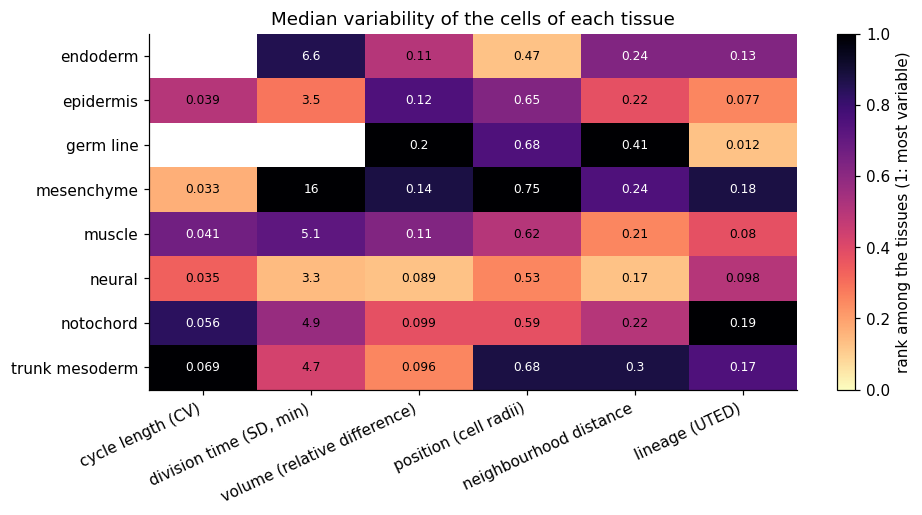

In [50]:
per_cell = pd.DataFrame({
    "cycle length (CV)": cv,
    "division time (SD, min)": spread,
    "volume (relative difference)": volume_diffs[volume_diffs.comparison == "between embryos"].groupby("name").difference.median(),
    "position (cell radii)": position_table[position_table.comparison == "between embryos"].groupby("name").distance.median(),
    "neighbourhood distance": neighbour_table[neighbour_table.comparison == "between embryos"].groupby("name").distance.median(),
    "lineage (UTED)": per_lineage,
})
print("rank correlations between the variability measures of the cells:")
print(per_cell.corr(method="spearman").round(2))
per_tissue = per_cell.groupby(tissues.reindex(per_cell.index).values).median()
per_tissue = per_tissue.drop(index=[t for t in ("unknown", "tail tip", "mixed") if t in per_tissue.index])
ranked = per_tissue.rank(pct=True)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
image = ax.imshow(ranked.values, cmap="magma_r", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(ranked.shape[1]), ranked.columns, rotation=25, ha="right")
ax.set_yticks(range(ranked.shape[0]), ranked.index)
for i in range(ranked.shape[0]):
    for j in range(ranked.shape[1]):
        value = per_tissue.values[i, j]
        ax.text(j, i, "" if np.isnan(value) else f"{value:.2g}", ha="center", va="center", fontsize=8,
                color="w" if ranked.values[i, j] > 0.6 else "k")
plt.colorbar(image, label="rank among the tissues (1: most variable)")
ax.set_title("Median variability of the cells of each tissue")
plt.show()

## 10. B7.7: variability or artefact?

B7.7, a mesenchyme precursor, has the most variable division time and the most
variable volume ratio of the embryo. Followed side by side, it behaves in two
ways. On 10 of the 13 sides observed, in six embryos, it divides at about 320
minutes into a tiny B8.13, 10 to 18 times smaller than its sister, which never
divides, and a large B8.14, which divides again at about 380 minutes. In
Phmamm-5-v2 (both sides) and on the `*` side of Phmamm-9-v2, it divides only
once, equally, at about 375 minutes: the time when B8.14 divides elsewhere.

Either B7.7 really buds off a tiny cell in most embryos, which would make it
the least reproducible division of the embryo, or the tiny "cell" is a
fragment that the segmentation took for a cell, and the names of the B7.7
lineage are shifted by one generation on ten sides. The data alone do not
settle it, but the coincidence of the times favours the second. It accounts
for the variable mesenchyme of sections 3 and 4, and for most of the births
more than 20 minutes off in the v2 embryos (next section).

In [51]:
rows = {}
for e in V2:
    t = tables[e]
    if "b7.0007_" not in t.index:
        continue
    for side in "_*":
        name = "b7.0007" + side
        if name not in t.index or np.isnan(t.at[name, "division"]):
            continue
        small, large = at.daughters(name)
        rows[f"{e} {at.conklin(name)}"] = {
            "B7.7 divides (min)": alignment.minutes(e, t.at[name, "division"]),
            "volume B8.14 / B8.13": t.volume.get(large, np.nan) / t.volume.get(small, np.nan),
            "B8.13 divides": not np.isnan(t.division.get(small, np.nan)),
            "B8.14 divides (min)": alignment.minutes(e, t.division.get(large, np.nan)),
        }
b77 = pd.DataFrame(rows).T
b77.round(1)

,B7.7 divides (min),volume B8.14 / B8.13,B8.13 divides,B8.14 divides (min)
Phmamm-1-v2 B7.7,315.738,11.632,False,386.116
Phmamm-1-v2 B7.7*,318.733,15.416,False,383.121
Phmamm-3-v2 B7.7,316.59,10.249,False,378.401
Phmamm-3-v2 B7.7*,318.408,16.8,False,376.583
Phmamm-4-v2 B7.7,320.88,14.016,False,NaN
Phmamm-4-v2 B7.7*,326.265,14.477,False,NaN
Phmamm-5-v2 B7.7,373.307,1.207,False,NaN
Phmamm-5-v2 B7.7*,376.74,1.237,False,NaN
Phmamm-7-v2 B7.7*,321.166,10.446,False,NaN
Phmamm-8-v2 B7.7,320.0,10.072,False,382.0


## 11. The 2020 reconstructions

Astec-Pm6 and Astec-Pm10 were not used for the atlas of Biasuz et al.
Compared with the consensus of the seven v2 embryos, after their alignment on
the cell numbers, their births deviate more: Astec-Pm10 has 80 births more
than 20 minutes off, against 0 to 4 in each v2 embryo (six of these eight in
the B7.7 lineage, see the list above the table). In Astec-Pm10, for instance,
the cells named B9.17 to B9.20 are born 95 minutes early.

These deviations could be errors of names or of tracking. The UTED, which
does not use the names below the root of a lineage, tells them apart: if only
the names were wrong, the lineages would be as alike as those of the v2
embryos.

In [52]:
consensus_birth = alignment.consensus("birth")
deviations_all, rows = {}, {}
for e in V2 + V1:
    if e in V2:
        deviation = alignment.deviations("birth")[e].dropna()
    else:
        births = alignment.to_reference(e, tables[e].birth)
        deviation = (births - consensus_birth.reindex(births.index)) * alignment.interval
        deviation = deviation[alignment.covers(e, consensus_birth.reindex(deviation.index))].dropna()
    deviations_all[e] = deviation
    off = deviation[deviation.abs() > 20]
    rows[e] = {"births compared": len(deviation), "median |deviation| (min)": deviation.abs().median(),
               "births more than 20 min off": len(off),
               "of which in the B-line": int(sum(at.founder(n) == "B" for n in off.index))}
print("v2 births more than 20 min off:", {e: sorted(at.conklin(n) for n in deviations_all[e][deviations_all[e].abs() > 20].index)
                                          for e in V2 if (deviations_all[e].abs() > 20).any()})
print("Astec-Pm10, largest deviations (min):",
      {at.conklin(n): round(v) for n, v in deviations_all["Astec-Pm10"].sort_values(key=abs).tail(8).items()})
pd.DataFrame(rows).T.round(2)

v2 births more than 20 min off: {'Phmamm-5-v2': ['B8.13', 'B8.13*', 'B8.14', 'B8.14*'], 'Phmamm-8-v2': ['B10.17', 'B10.18'], 'Phmamm-9-v2': ['B8.13*', 'B8.14*']}
Astec-Pm10, largest deviations (min): {'B9.30*': -70, 'B9.29*': -70, 'B9.4': -80, 'B9.3': -80, 'B9.20*': -95, 'B9.19*': -95, 'B9.18*': -95, 'B9.17*': -95}


,births compared,median |deviation| (min),births more than 20 min off,of which in the B-line
Phmamm-1-v2,544.0,2.64,0.0,0.0
Phmamm-3-v2,310.0,1.94,0.0,0.0
Phmamm-4-v2,306.0,2.54,0.0,0.0
Phmamm-5-v2,308.0,3.19,4.0,4.0
Phmamm-7-v2,278.0,2.55,0.0,0.0
Phmamm-8-v2,566.0,3.12,2.0,2.0
Phmamm-9-v2,208.0,2.12,2.0,2.0
Astec-Pm6,294.0,2.96,8.0,2.0
Astec-Pm10,607.0,6.04,80.0,32.0


They are not: the lineages of the vegetal cells (A and B lines) of the v1
embryos differ from those of the v2 embryos twice as much as the v2 embryos
differ from each other, and Astec-Pm10 is the furthest. The lineages
themselves differ, not only the names. Biasuz et al. corrected such
inconsistencies when they made the v2 releases of the other embryos, and left
these two out of their atlas; comparing many embryos is a way to find them.

In [53]:
v1_lineages = at.lineage_distances(embryos, alignment, START, END, V2 + V1, sides=False)
v1_lineages["line"] = [at.founder(n) for n in v1_lineages.name]
v1_lineages["pair"] = ["v1 against v2" if (a in V1) != (b in V1) else ("v2 against v2" if a in V2 else "v1 against v1")
                       for a, b in zip(v1_lineages.embryo, v1_lineages.other)]
print("median normalised UTED between the lineages of the same cells, by founder line:")
table_v1 = v1_lineages.groupby(["pair", "line"]).distance.median().unstack().round(3)
pm10_rows = v1_lineages[(v1_lineages.embryo == "Astec-Pm10") | (v1_lineages.other == "Astec-Pm10")]
pm10_rows = pm10_rows[~pm10_rows[["embryo", "other"]].isin(["Astec-Pm6"]).any(axis=1)]
table_v1.loc["Astec-Pm10 against v2"] = pm10_rows.groupby("line").distance.median().round(3)
table_v1

median normalised UTED between the lineages of the same cells, by founder line:


line,A,B,a,b
pair,,,,
v1 against v1,0.199,0.487,0.176,0.111
v1 against v2,0.161,0.164,0.118,0.100
v2 against v2,0.088,0.096,0.089,0.089
Astec-Pm10 against v2,0.246,0.213,0.130,0.098


## 12. Conclusions

| | Guignard et al. 2020 and Biasuz et al. 2025 | this notebook |
|---|---|---|
| timing | lifespans of matched cells differ by less than 10% | 4% median, the same between embryos and between sides |
| volume | less than 10% | 10% median between embryos, 8% between sides |
| neighbours | 5 to 6 per cell | 5 to 6 |
| neighbourhoods | about 20% different between embryos, 60% between sisters | 13% to 29% (64-cell stage to early neurula), 58% between sisters |
| contacts | more than 80% of the cells share 80% of their neighbours | 75% of the cells |
| lineages | UTED below 10% between matched lineages | 9% median between embryos, 7% between sides |
| sister lineages | asymmetric divisions are mostly fate restrictions | divergence higher when the daughters make different tissues (AUC 0.69) |
| orientations | asymmetric divisions are more precisely oriented | yes (10 vs 12 degrees) |

The embryos of *Phallusia mammillata* are reproducible cell by cell, once their
different paces are taken out by a single linear transformation of time.
Matched cells differ between embryos about as much as between the two sides
of one embryo, in timing, volume, position, contacts and lineage: most of the
variability is local, not a different plan in each embryo, although a part
of it (a correlation of about 0.35 between the two sides) is shared by the
whole embryo. Timing and
geometry vary independently, the large contacts on which inductions rely are
the most stable, and the programmed asymmetries (sister asynchronies, unequal
divisions, divergent sister lineages) are reproduced in every embryo.

**Limits.** Seven embryos, whose common window covers 270 to 354 minutes
only; one embryo reaches the tailbud. The names of the v2 embryos were given
by matching neighbourhoods with reference embryos, which can make the
neighbourhoods and positions look more alike than they are; the timing is
independent of the naming. The tissues come from the fate map, through the
names, not from markers.

**For `lineagetree`.** Three things were needed beyond the library:
`read_from_ASTEC` stores the names in a `label` property that the `labels` of
the tree do not use (hence `change_labels("label")`); `LineageTreeManager`
needs a time resolution on every tree it holds, even those it does not
compare; and the time resolution is stored in tenths, hence the factor 100.

## 13. Two recap figures

The two figures below sum up the notebook, one per 16:9 slide. The first
compares, property by property, the same cell in two embryos (blue) with the
same cell on the two sides of one embryo (orange). The second shows which
differences are reproducible: sister asynchronies, unequal divisions,
contacts by size, sister lineages and tissues, and the one division that is
not, B7.7. The code is in `at.recap_variability` and `at.recap_structure`;
after either cell, `figure.savefig("recap.pdf")` exports its figure.

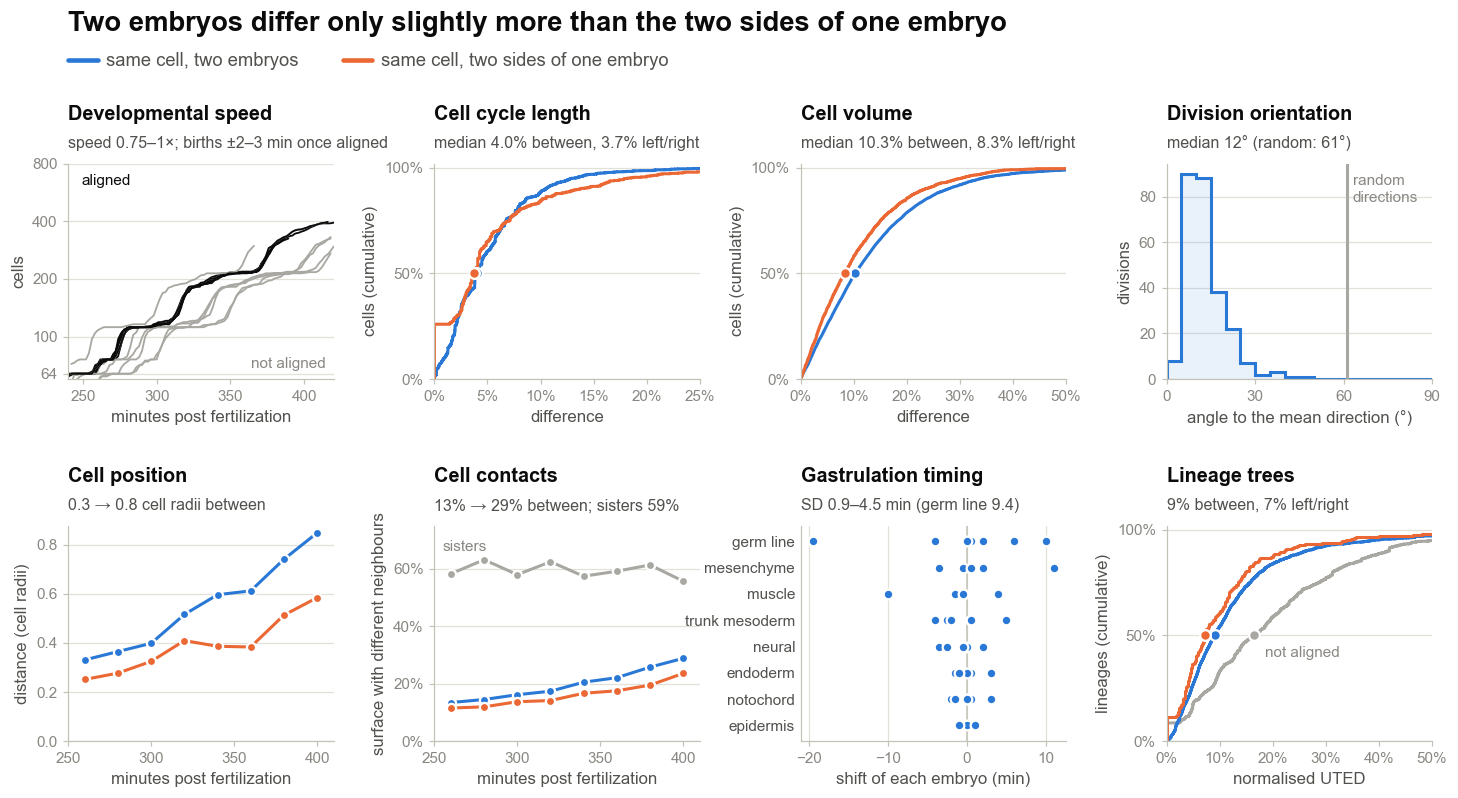

In [54]:
figure = at.recap_variability(counts, alignment, V2, cycle_diffs, volume_diffs, angles, position_table,
                              neighbour_table, shifts, lineages, naive)
plt.show()

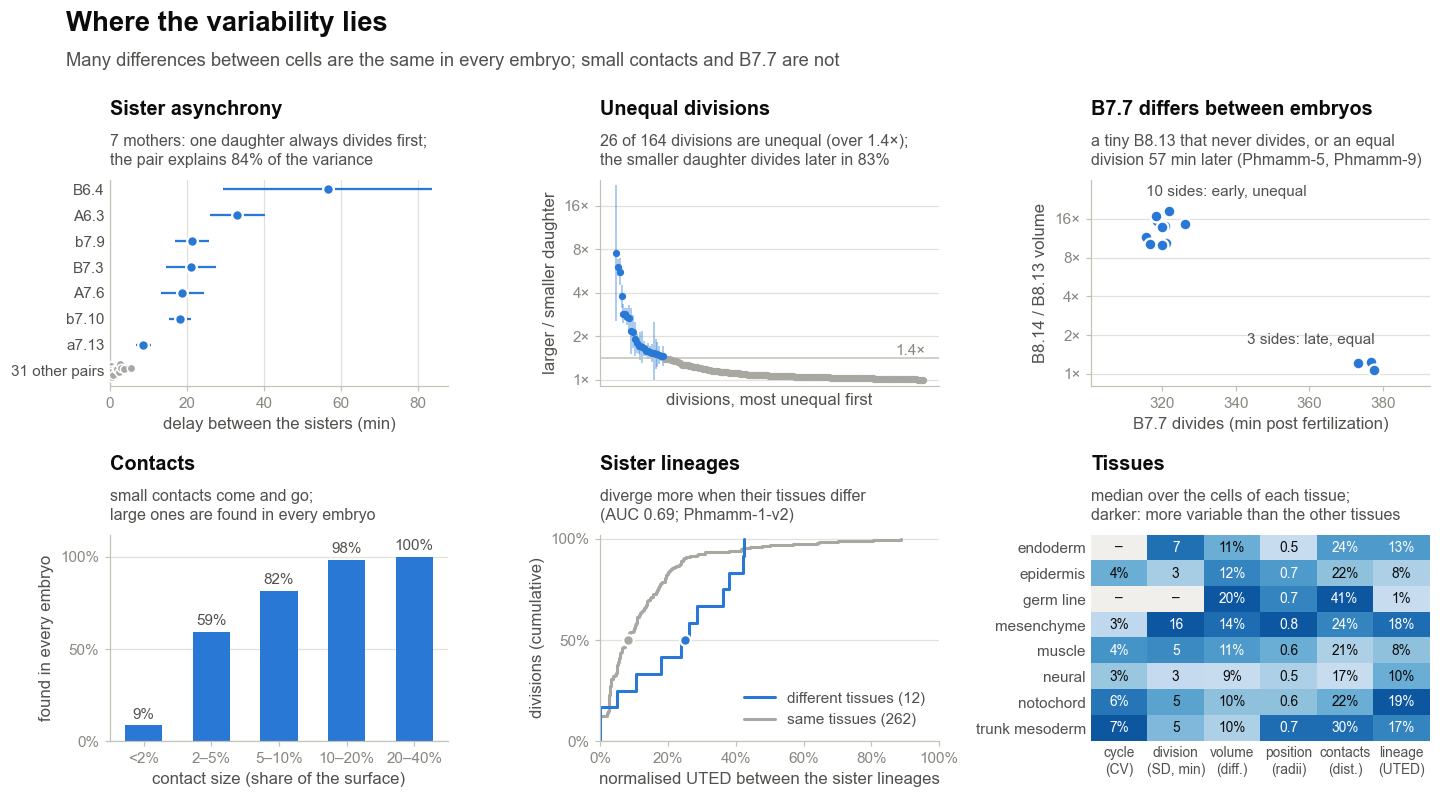

In [55]:
figure = at.recap_structure(asynchrony, pairs, programmed, per_division, sisters_cycle, by_size, sisters_P1,
                            per_tissue, b77)
plt.show()

## 14. Seven simple examples

One figure per slide, each showing one kind of variability with a single
example.

Five figures follow the same cell, a8.30, an epidermis precursor, in the
seven named embryos. The filled dots are a8.30 and the open dots its
bilateral homologue a8.30\* in the same embryos. It was chosen because it is
ordinary: on the spread of its division times, its volume, its position, its
neighbourhood and the axis of its division, both copies rank between the
22nd and the 87th percentiles of the named cells, 54th on average. A cell
seen dividing in all seven movies is an early one; later cells vary more
(section 6 and `phallusia_tissue_time_variability.ipynb`).

1. **Pace.** The only figure in movie time, before the alignment of section
   2: going from 76 to 218 cells takes 94 to 122 minutes depending on the
   embryo. The other figures are in reference minutes.
2. **Division times.** a8.30 divides within 9 minutes in the 14 copies, for a
   cycle of about 43 minutes.
3. **Volumes.** The largest copy is 1.6 times the smallest; the two sides of
   one embryo can differ more than two embryos.
4. **Position.** The registered positions of the cell at 300 minutes,
   drawn over the cells of the reference embryo seen from the side of
   a8.30, with the anterior to the left: they land on the cell or next to it.
5. **Axis of division.** Each line is at its true angle to the average axis
   of the seven embryos; the dashed lines show the median angle that random
   axes would have.
6. **Contacts.** At 300 minutes, the large contacts are found in every
   embryo, and some of the small ones come and go (section 7).
7. **Lineage tree.** a7.15, the mother of a8.30, and its descendants over
   the time that all the movies cover: the same tree in every embryo, with
   divisions a few minutes apart.

The code is in `at.pace_example`, `at.dot_example`, `at.position_example`,
`at.axis_example`, `at.contact_example` and `at.lineage_example`; after any
cell, `figure.savefig("example.pdf")` exports its figure.

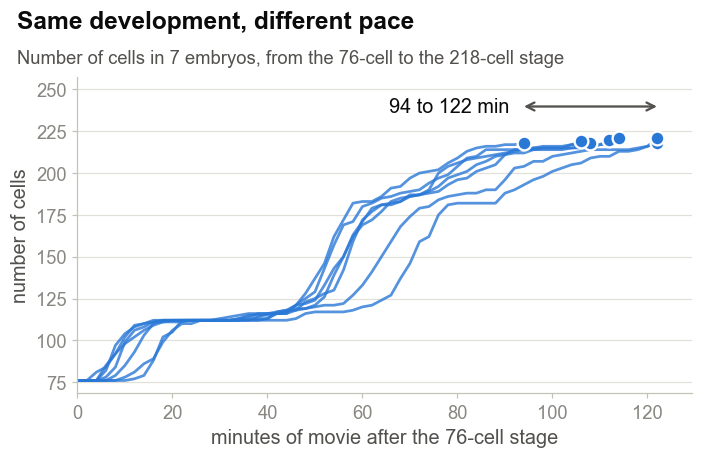

In [56]:
EXAMPLE = "a8.0007_"  # a8.30, an epidermis precursor
EXAMPLE_TIME = 30  # reference time point: 300 minutes post fertilization
example_name = at.conklin(EXAMPLE)
example_minutes = alignment.minutes(at.REFERENCE, EXAMPLE_TIME)
figure = at.pace_example(counts, V2)
plt.show()

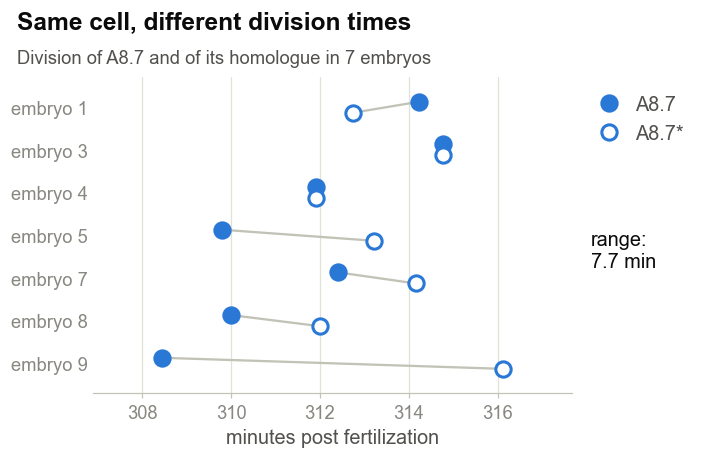

In [57]:
figure = at.dot_example(at.cell_in_embryos(at.event_minutes(alignment), V2, EXAMPLE),
                        "Same cell, different division times",
                        f"Division of {example_name} and of its homologue in 7 embryos",
                        "minutes post fertilization", unit=" min")
plt.show()

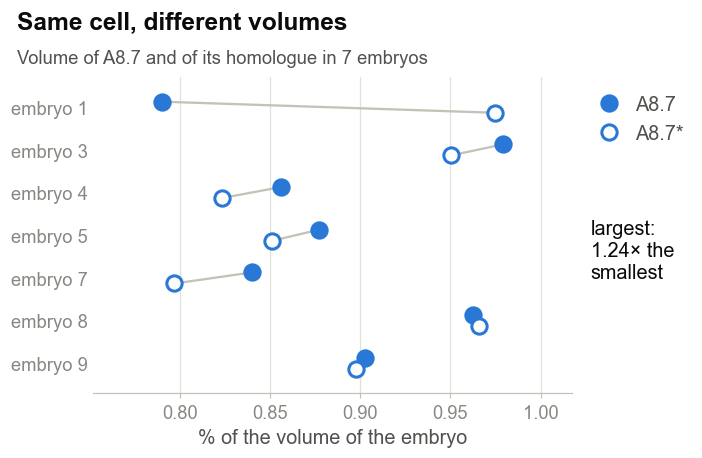

In [58]:
figure = at.dot_example(at.cell_in_embryos(volumes * 100, V2, EXAMPLE),
                        "Same cell, different volumes",
                        f"Volume of {example_name} and of its homologue in 7 embryos",
                        "% of the volume of the embryo", ratio=True)
plt.show()

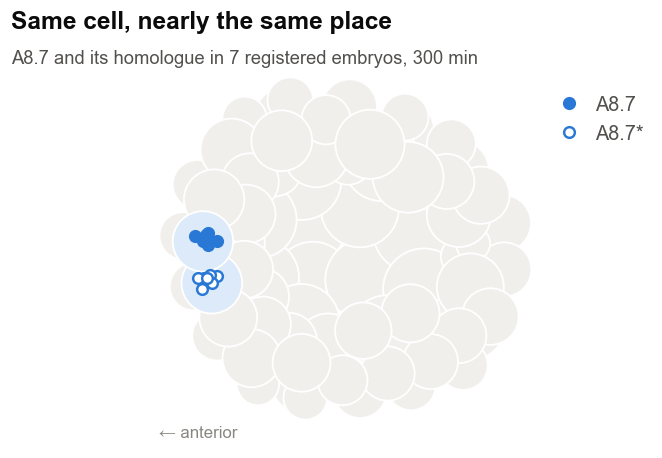

In [59]:
figure = at.position_example(embryos, alignment, EXAMPLE_TIME, V2, EXAMPLE)
plt.show()

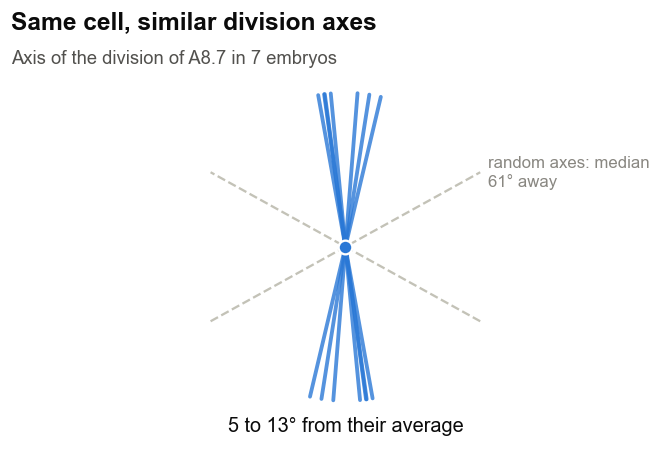

In [60]:
figure = at.axis_example(oriented, EXAMPLE)
plt.show()

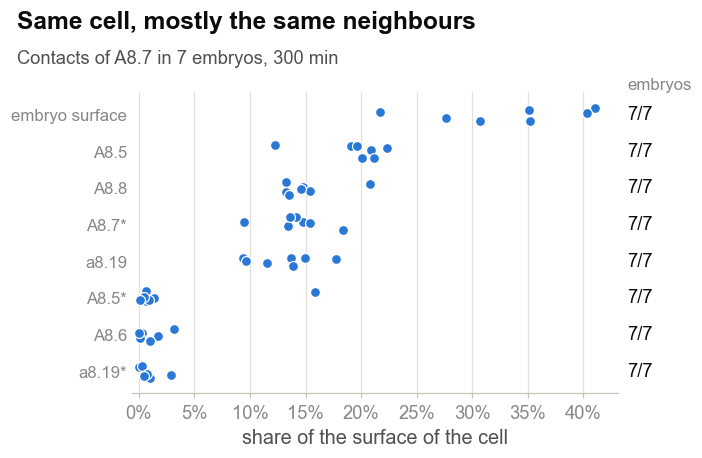

In [61]:
example_contacts = at.cell_contacts(neighbourhoods[EXAMPLE_TIME], EXAMPLE, V2)
figure = at.contact_example(example_contacts, example_name, example_minutes)
plt.show()

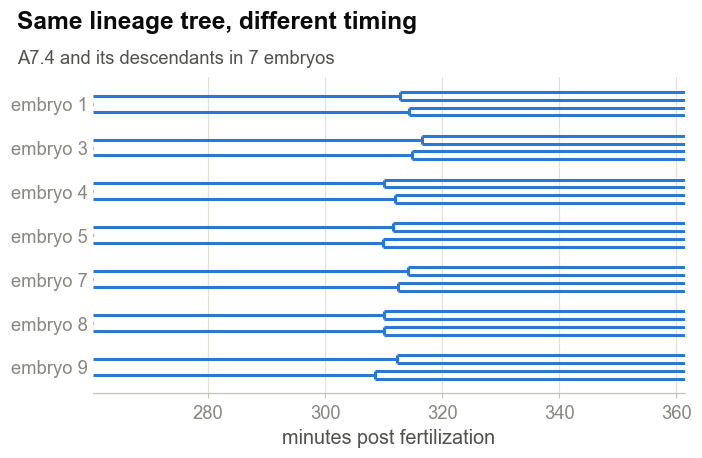

In [62]:
figure = at.lineage_example(tables, alignment, V2, at.mother(EXAMPLE))
plt.show()